TIM MAHASISWA BUTUH LIBUR

BAGIAN 1: Environment Setup & Library Import

In [25]:
import subprocess, sys
packages = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'sklearn', 'scipy']
for pkg in packages:
    try:
        mod = __import__(pkg)
        print(f" {pkg}: {mod.__version__}")
    except (ImportError, AttributeError):
        print(f": NOT INSTALLED — jalankan: pip install {pkg}")

 pandas: 2.2.3
 numpy: 2.1.3
 matplotlib: 3.10.0
 seaborn: 0.13.2
 sklearn: 1.6.1
 scipy: 1.16.3


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_squared_error, r2_score, mean_absolute_error,
                             silhouette_score, classification_report, confusion_matrix)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from matplotlib.gridspec import GridSpec
from scipy.cluster.hierarchy import dendrogram, linkage

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette('Set2')

COLOR_PRIMARY   = '#1a6b5c'
COLOR_SECONDARY = '#2eb8a0'
COLOR_ACCENT    = '#f4a62a'
COLOR_DARK      = '#1e2d3d'
COLOR_LIGHT     = '#e8f5f3'

PALETTE = [COLOR_PRIMARY, COLOR_SECONDARY, COLOR_ACCENT, '#e05c5c', '#7b5ea7', '#3a87c5']

print(" Semua library berhasil diimport!")
print(f"   Pandas   : {pd.__version__}")
print(f"   NumPy    : {np.__version__}")
print(f"   Seaborn  : {sns.__version__}")

 Semua library berhasil diimport!
   Pandas   : 2.2.3
   NumPy    : 2.1.3
   Seaborn  : 0.13.2


BAGIAN 2: Data Loading dari Dataset BPS

In [28]:
import os
DATA_DIR = r"DATASET"

file_produksi = os.path.join(DATA_DIR,
    "/content/Volume Produksi dan Nilai Produksi Perikanan Tangkap Menurut Provinsi dan Jenis Penangkapan, 2024.csv")

file_darat = os.path.join(DATA_DIR,
    "/content/Volume Produksi dan Nilai Produksi Perikanan Tangkap di Perairan Darat Menurut Provinsi dan Lokasi, 2024.csv")

file_tpt_prov = os.path.join(DATA_DIR,
    "/content/Tingkat Pengangguran Terbuka (TPT) dan Tingkat Partisipasi Angkatan Kerja (TPAK) Menurut Provinsi, 2025.csv")

file_tpt_2023 = os.path.join(DATA_DIR,
    "/content/Tingkat Pengangguran Terbuka menurut Jenis Kelamin dan Kabupaten_Kota , 2023.csv")
file_tpt_2024 = os.path.join(DATA_DIR,
    "/content/Tingkat Pengangguran Terbuka menurut Jenis Kelamin dan Kabupaten_Kota , 2024.csv")
file_tpt_2025 = os.path.join(DATA_DIR,
    "/content/Tingkat Pengangguran Terbuka menurut Jenis Kelamin dan Kabupaten_Kota , 2025 (1).csv")

def load_tpt_kabkota(filepath, year):
    """Load file TPT kabupaten/kota dari format BPS."""
    df = pd.read_csv(filepath, header=None, encoding='utf-8-sig')

    data_rows = []
    current_prov = None
    for idx, row in df.iterrows():
        if idx < 4:
            continue
        name = str(row[0]).strip()
        val_lk  = str(row[1]).strip()
        val_pr  = str(row[2]).strip()
        val_tot = str(row[3]).strip()
        if name == '' or name == 'nan':
            continue
        is_prov = name.isupper()
        if is_prov:
            current_prov = name.title()
        try:
            lk  = float(val_lk)  if val_lk  not in ['-','nan',''] else np.nan
            pr  = float(val_pr)  if val_pr  not in ['-','nan',''] else np.nan
            tot = float(val_tot) if val_tot not in ['-','nan',''] else np.nan
        except:
            continue
        data_rows.append({
            'provinsi': current_prov,
            'wilayah': name,
            'is_provinsi': is_prov,
            f'tpt_lk_{year}': lk,
            f'tpt_pr_{year}': pr,
            f'tpt_total_{year}': tot
        })
    return pd.DataFrame(data_rows)

df_prod = pd.read_csv(file_produksi, encoding='utf-8-sig')
df_darat = pd.read_csv(file_darat, encoding='utf-8-sig')
df_tpt_prov = pd.read_csv(file_tpt_prov, encoding='utf-8-sig')
df_tpt_23 = load_tpt_kabkota(file_tpt_2023, 2023)
df_tpt_24 = load_tpt_kabkota(file_tpt_2024, 2024)
df_tpt_25 = load_tpt_kabkota(file_tpt_2025, 2025)

print("Dataset berhasil dimuat:")
print(f"  [1] Produksi Perikanan (Provinsi)    : {df_prod.shape[0]} baris × {df_prod.shape[1]} kolom")
print(f"  [2] Produksi Perairan Darat (Lokasi) : {df_darat.shape[0]} baris × {df_darat.shape[1]} kolom")
print(f"  [3] TPT & TPAK Provinsi 2025         : {df_tpt_prov.shape[0]} baris × {df_tpt_prov.shape[1]} kolom")
print(f"  [4] TPT Kab/Kota 2023                : {df_tpt_23.shape[0]} baris")
print(f"  [5] TPT Kab/Kota 2024                : {df_tpt_24.shape[0]} baris")
print(f"  [6] TPT Kab/Kota 2025                : {df_tpt_25.shape[0]} baris")

Dataset berhasil dimuat:
  [1] Produksi Perikanan (Provinsi)    : 39 baris × 7 kolom
  [2] Produksi Perairan Darat (Lokasi) : 39 baris × 11 kolom
  [3] TPT & TPAK Provinsi 2025         : 39 baris × 5 kolom
  [4] TPT Kab/Kota 2023                : 579 baris
  [5] TPT Kab/Kota 2024                : 579 baris
  [6] TPT Kab/Kota 2025                : 579 baris


BAGIAN 3: Exploratory Data Analysis (EDA) & Data Storytelling

In [29]:
print("=" * 60)
print("DATASET 1: PRODUKSI PERIKANAN TANGKAP 2024")
print("=" * 60)
print("\n Kolom:")
for col in df_prod.columns:
    print(f"  • {col}")

print("\n 5 Baris Pertama:")
display(df_prod.head())

print("\n statistik Deskriptif:")
display(df_prod.describe())

print("\n Missing Values:")
print(df_prod.isnull().sum())

DATASET 1: PRODUKSI PERIKANAN TANGKAP 2024

 Kolom:
  • Provinsi
  • Produksi Perikanan Tangkap di Laut (kg)- Interoperabilitas (Kg)
  • Nilai Produksi Perikanan Tangkap di Laut (rupiah) - Interoperabilitas (Rp)
  • Produksi Perikanan Tangkap di Perairan Darat (ton) - Interoperabilitas (Kg)
  • Nilai Produksi Perikanan Tangkap di Perairan Darat (rupiah) - Interoperabilitas (Rp)
  • Produksi Perikanan Tangkap (kg) - Interoperabilitas (Kg)
  • Nilai Produksi Perikanan Tangkap (rupiah) - Interoperabilitas (Rp)

 5 Baris Pertama:


,Provinsi,Produksi Perikanan Tangkap di Laut (kg)- Interoperabilitas (Kg),Nilai Produksi Perikanan Tangkap di Laut (rupiah) - Interoperabilitas (Rp),Produksi Perikanan Tangkap di Perairan Darat (ton) - Interoperabilitas (Kg),Nilai Produksi Perikanan Tangkap di Perairan Darat (rupiah) - Interoperabilitas (Rp),Produksi Perikanan Tangkap (kg) - Interoperabilitas (Kg),Nilai Produksi Perikanan Tangkap (rupiah) - Interoperabilitas (Rp)
0,Aceh,422025289,13594776984953,5614432,204725612000,427639721,13799502596953
1,Sumatera Utara,381128980,11407678006156,14689686,505146038950,395818666,11912824045106
2,Sumatera Barat,220024824,6333999074548,12389623,513016268000,232414447,6847015342548
3,Riau,105459180,3090712315500,20316385,876867109000,125775565,3967579424500
4,Jambi,46417185,1631817847763,7276883,236568723725,53694068,1868386571488



 statistik Deskriptif:


,Produksi Perikanan Tangkap (kg) - Interoperabilitas (Kg),Nilai Produksi Perikanan Tangkap (rupiah) - Interoperabilitas (Rp)
count,3.900000e+01,3.900000e+01
mean,4.005956e+08,1.122171e+13
std,1.228043e+09,3.433730e+13
min,1.714550e+05,6.557760e+09
25%,8.014994e+07,2.558842e+12
50%,1.979036e+08,5.514666e+12
75%,3.023353e+08,8.538210e+12
max,7.811614e+09,2.188234e+14



 Missing Values:
Provinsi                                                                                0
Produksi Perikanan Tangkap di Laut (kg)- Interoperabilitas (Kg)                         0
Nilai Produksi Perikanan Tangkap di Laut (rupiah) - Interoperabilitas (Rp)              0
Produksi Perikanan Tangkap di Perairan Darat (ton) - Interoperabilitas (Kg)             0
Nilai Produksi Perikanan Tangkap di Perairan Darat (rupiah) - Interoperabilitas (Rp)    0
Produksi Perikanan Tangkap (kg) - Interoperabilitas (Kg)                                0
Nilai Produksi Perikanan Tangkap (rupiah) - Interoperabilitas (Rp)                      0
dtype: int64


In [31]:
print("-" * 60)
print("DATASET 3: TPT & TPAK PROVINSI 2025")
print("-" * 60)
display(df_tpt_prov.head(10))
print("\n Statistik Deskriptif:")
display(df_tpt_prov.describe())

print("\n Distribusi TPT (Agustus 2025):")
print(f"  Rata-rata  : {df_tpt_prov['Tingkat Pengangguran Terbuka (TPT) - Agustus'].mean():.2f}%")
print(f"  Median     : {df_tpt_prov['Tingkat Pengangguran Terbuka (TPT) - Agustus'].median():.2f}%")
print(f"  Max        : {df_tpt_prov['Tingkat Pengangguran Terbuka (TPT) - Agustus'].max():.2f}% ({df_tpt_prov.loc[df_tpt_prov['Tingkat Pengangguran Terbuka (TPT) - Agustus'].idxmax(), 'Provinsi']})")
print(f"  Min        : {df_tpt_prov['Tingkat Pengangguran Terbuka (TPT) - Agustus'].min():.2f}% ({df_tpt_prov.loc[df_tpt_prov['Tingkat Pengangguran Terbuka (TPT) - Agustus'].idxmin(), 'Provinsi']})")

------------------------------------------------------------
DATASET 3: TPT & TPAK PROVINSI 2025
------------------------------------------------------------


,Provinsi,Tingkat Pengangguran Terbuka (TPT) - Februari,Tingkat Pengangguran Terbuka (TPT) - Agustus,Tingkat Partisipasi Angkatan Kerja (TPAK) - Februari,Tingkat Partisipasi Angkatan Kerja (TPAK) - Agustus
0,Aceh,5.50,5.64,65.63,65.32
1,Sumatera Utara,5.05,5.32,70.13,72.29
2,Sumatera Barat,5.69,5.62,70.95,71.34
3,Riau,4.12,4.16,64.68,66.55
4,Jambi,4.48,4.26,67.11,68.37
5,Sumatera Selatan,3.89,3.69,70.56,69.88
6,Bengkulu,3.24,3.41,71.50,71.78
7,Lampung,4.07,4.21,71.16,70.44
8,Kepulauan Bangka Belitung,4.17,4.45,67.67,69.38
9,Kepulauan Riau,6.89,6.45,66.84,68.23



 Statistik Deskriptif:


,Tingkat Pengangguran Terbuka (TPT) - Februari,Tingkat Pengangguran Terbuka (TPT) - Agustus,Tingkat Partisipasi Angkatan Kerja (TPAK) - Februari,Tingkat Partisipasi Angkatan Kerja (TPAK) - Agustus
count,39.000000,39.000000,39.000000,39.000000
mean,4.438205,4.477949,70.363333,70.518718
std,1.371720,1.364361,4.534798,4.702323
min,1.580000,1.490000,64.680000,63.980000
25%,3.370000,3.540000,67.540000,67.510000
50%,4.210000,4.210000,69.900000,69.570000
75%,5.415000,5.470000,71.475000,72.345000
max,6.920000,6.960000,88.270000,90.660000



 Distribusi TPT (Agustus 2025):
  Rata-rata  : 4.48%
  Median     : 4.21%
  Max        : 6.96% (Papua)
  Min        : 1.49% (Bali)


In [34]:
df_p = df_prod.copy()
df_p.columns = ['Provinsi', 'Vol_Laut_kg', 'Nilai_Laut_Rp',
                  'Vol_Darat_kg', 'Nilai_Darat_Rp',
                  'Vol_Total_kg', 'Nilai_Total_Rp']

df_p = df_p[df_p['Provinsi'] != 'Indonesia'].copy()

for col in df_p.columns[1:]:
    df_p[col] = pd.to_numeric(df_p[col].replace('-', np.nan), errors='coerce')

df_p['Vol_Laut_ton']  = df_p['Vol_Laut_kg'] / 1000
df_p['Vol_Darat_ton'] = df_p['Vol_Darat_kg'] / 1000
df_p['Vol_Total_ton'] = df_p['Vol_Total_kg'] / 1000
df_p['Nilai_Total_M'] = df_p['Nilai_Total_Rp'] / 1e9

print("Data produksi")
print(f"\n🇮🇩 GAMBARAN PERIKANAN INDONESIA 2024:")
total_laut = df_p['Vol_Laut_ton'].sum()
total_darat = df_p['Vol_Darat_ton'].sum()
total_val = df_p['Nilai_Total_M'].sum()
print(f"   Total Produksi Laut   : {total_laut:,.0f} ton")
print(f"   Total Produksi Darat  : {total_darat:,.0f} ton")
print(f"   Total Nilai Produksi  : Rp {total_val:,.1f} Milyar")

top10_laut = df_p.nlargest(10, 'Vol_Laut_ton')
print(f"\n Top 10 Provinsi Produksi Perikanan Laut:")
for i, row in top10_laut.iterrows():
    print(f"   {row['Provinsi']:30s}: {row['Vol_Laut_ton']:>10,.0f} ton")

Data produksi

🇮🇩 GAMBARAN PERIKANAN INDONESIA 2024:
   Total Produksi Laut   : 7,330,891 ton
   Total Produksi Darat  : 480,723 ton
   Total Nilai Produksi  : Rp 218,823.4 Milyar

 Top 10 Provinsi Produksi Perikanan Laut:
   Jawa Timur                    :    619,053 ton
   Jawa Tengah                   :    528,259 ton
   Sulawesi Selatan              :    466,673 ton
   Aceh                          :    422,025 ton
   Maluku                        :    399,143 ton
   Sumatera Utara                :    381,129 ton
   Kepulauan Riau                :    339,329 ton
   Sulawesi Utara                :    336,186 ton
   Maluku Utara                  :    318,734 ton
   Sulawesi Tenggara             :    270,452 ton


BAGIAN 4: Data Cleaning & Handling Missing Values

In [35]:
print("=" * 55)
print("DATA CLEANING REPORT")
print("=" * 55)

print("\n[1] Missing Values per Kolom (df_prod):")
mv = df_p.isnull().sum()
mv_pct = (mv / len(df_p) * 100).round(2)
mv_df = pd.DataFrame({'Missing': mv, 'Pct (%)': mv_pct})
print(mv_df[mv_df['Missing'] > 0].to_string())

fill_cols = ['Vol_Darat_kg', 'Nilai_Darat_Rp', 'Vol_Darat_ton']
df_p[fill_cols] = df_p[fill_cols].fillna(0)
print("\n[2] Nilai NaN pada kolom perairan darat → diisi dengan 0 (tidak ada data = tidak ada produksi)")

dupes = df_p.duplicated().sum()
print(f"\n[3] Data Duplikat: {dupes} baris")

df_p['check'] = (df_p['Vol_Laut_kg'].fillna(0) + df_p['Vol_Darat_kg'].fillna(0))
df_p['selisih'] = abs(df_p['Vol_Total_kg'].fillna(0) - df_p['check'])
inconsistent = df_p[df_p['selisih'] > 100]
print(f"\n[4] Inkonsistensi Total Volume: {len(inconsistent)} baris (threshold 100 kg)")
df_p.drop(columns=['check', 'selisih'], inplace=True)

df_tpt = df_tpt_prov.copy()
df_tpt.columns = ['Provinsi', 'TPT_Feb', 'TPT_Ags', 'TPAK_Feb', 'TPAK_Ags']
df_tpt = df_tpt[df_tpt['Provinsi'] != 'Indonesia'].copy()
df_tpt[['TPT_Feb','TPT_Ags','TPAK_Feb','TPAK_Ags']] = df_tpt[['TPT_Feb','TPT_Ags','TPAK_Feb','TPAK_Ags']].apply(pd.to_numeric, errors='coerce')

print(f"\n[5] Data TPT Provinsi → {len(df_tpt)} provinsi valid")

prov_map = {
    'Aceh': 'Aceh', 'Sumatera Utara': 'Sumatera Utara',
    'Sumatera Barat': 'Sumatera Barat', 'Riau': 'Riau',
    'Jambi': 'Jambi', 'Sumatera Selatan': 'Sumatera Selatan',
    'Bengkulu': 'Bengkulu', 'Lampung': 'Lampung',
    'Kepulauan Bangka Belitung': 'Kepulauan Bangka Belitung',
    'Kepulauan Riau': 'Kepulauan Riau',
    'DKI Jakarta': 'Dki Jakarta', 'Jawa Barat': 'Jawa Barat',
    'Jawa Tengah': 'Jawa Tengah', 'DI Yogyakarta': 'Di Yogyakarta',
    'Jawa Timur': 'Jawa Timur', 'Banten': 'Banten',
    'Bali': 'Bali', 'Nusa Tenggara Barat': 'Nusa Tenggara Barat',
    'Nusa Tenggara Timur': 'Nusa Tenggara Timur',
    'Kalimantan Barat': 'Kalimantan Barat',
    'Kalimantan Tengah': 'Kalimantan Tengah',
    'Kalimantan Selatan': 'Kalimantan Selatan',
    'Kalimantan Timur': 'Kalimantan Timur',
    'Kalimantan Utara': 'Kalimantan Utara',
    'Sulawesi Utara': 'Sulawesi Utara', 'Sulawesi Tengah': 'Sulawesi Tengah',
    'Sulawesi Selatan': 'Sulawesi Selatan', 'Sulawesi Tenggara': 'Sulawesi Tenggara',
    'Gorontalo': 'Gorontalo', 'Sulawesi Barat': 'Sulawesi Barat',
    'Maluku': 'Maluku', 'Maluku Utara': 'Maluku Utara',
    'Papua Barat': 'Papua Barat', 'Papua Barat Daya': 'Papua Barat Daya',
    'Papua': 'Papua', 'Papua Selatan': 'Papua Selatan',
    'Papua Tengah': 'Papua Tengah', 'Papua Pegunungan': 'Papua Pegunungan'
}

print("\n Cleaning selesaiiiiiiiiii")

DATA CLEANING REPORT

[1] Missing Values per Kolom (df_prod):
                Missing  Pct (%)
Vol_Laut_kg           1     2.63
Nilai_Laut_Rp         1     2.63
Vol_Darat_kg          5    13.16
Nilai_Darat_Rp        5    13.16
Vol_Laut_ton          1     2.63
Vol_Darat_ton         5    13.16

[2] Nilai NaN pada kolom perairan darat → diisi dengan 0 (tidak ada data = tidak ada produksi)

[3] Data Duplikat: 0 baris

[4] Inkonsistensi Total Volume: 0 baris (threshold 100 kg)

[5] Data TPT Provinsi → 38 provinsi valid

 Cleaning selesaiiiiiiiiii


BAGIAN 5: Deteksi & Penanganan Outlier

LAPORAN OUTLIER:
--------------------------------------------------

[Vol_Laut_ton]
  IQR bounds  : [-192,758.9, 548,378.7]
  Outlier IQR : 1 (['Jawa Timur'])
  Outlier Z   : 1 baris

[Vol_Total_ton]
  IQR bounds  : [-231,717.3, 592,997.1]
  Outlier IQR : 1 (['Jawa Timur'])
  Outlier Z   : 1 baris

[Nilai_Total_M]
  IQR bounds  : [-6,446.0, 17,126.0]
  Outlier IQR : 0 (tidak ada)
  Outlier Z   : 0 baris


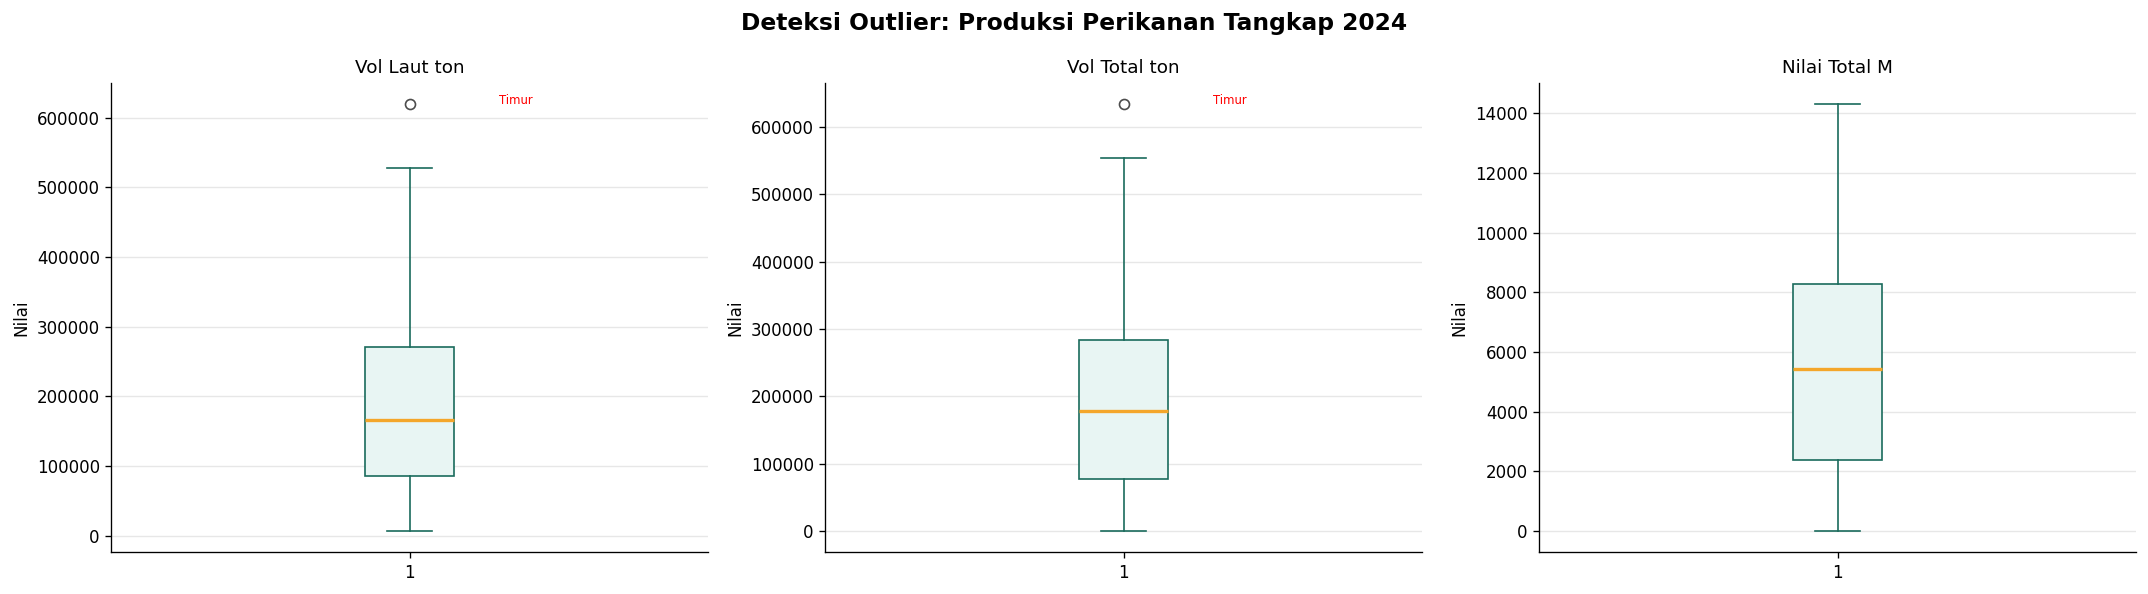


 Grafik tersimpan: output_outlier_boxplot.png


In [36]:
def detect_outliers_iqr(df, col):
    """Deteksi outlier menggunakan metode IQR."""
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    return outliers, lower, upper

def detect_outliers_zscore(df, col, threshold=2.5):
    """Deteksi outlier menggunakan Z-Score."""
    z = np.abs(stats.zscore(df[col].dropna()))
    return df[col].dropna().index[z > threshold].tolist()

target_cols = ['Vol_Laut_ton', 'Vol_Total_ton', 'Nilai_Total_M']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Deteksi Outlier: Produksi Perikanan Tangkap 2024', fontsize=14, fontweight='bold')

print("LAPORAN OUTLIER:")
print("-" * 50)

for i, col in enumerate(target_cols):
    series = df_p[col].dropna()
    outliers_iqr, low, high = detect_outliers_iqr(df_p.dropna(subset=[col]), col)
    outliers_z = detect_outliers_zscore(df_p, col)

    print(f"\n[{col}]")
    print(f"  IQR bounds  : [{low:,.1f}, {high:,.1f}]")
    print(f"  Outlier IQR : {len(outliers_iqr)} ({outliers_iqr['Provinsi'].tolist() if len(outliers_iqr) > 0 else 'tidak ada'})")
    print(f"  Outlier Z   : {len(outliers_z)} baris")

    # Boxplot
    ax = axes[i]
    bp = ax.boxplot(series, patch_artist=True, notch=False,
                    boxprops=dict(facecolor=COLOR_LIGHT, color=COLOR_PRIMARY),
                    medianprops=dict(color=COLOR_ACCENT, linewidth=2),
                    whiskerprops=dict(color=COLOR_PRIMARY),
                    capprops=dict(color=COLOR_PRIMARY),
                    flierprops=dict(marker='o', color='red', markersize=6, alpha=0.7))
    ax.set_title(col.replace('_', ' '), fontsize=11)
    ax.set_ylabel('Nilai')
    ax.grid(axis='y', alpha=0.3)

    # Anotasi outlier
    for _, row in outliers_iqr.iterrows():
        ax.annotate(row['Provinsi'].split()[-1],
                    xy=(1, row[col]), xytext=(1.15, row[col]),
                    fontsize=7, color='red', ha='left')

plt.tight_layout()
plt.savefig('output_outlier_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n Grafik tersimpan: output_outlier_boxplot.png")

In [37]:
def cap_outliers(df, col, method='iqr', factor=1.5):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - factor * IQR
    upper = Q3 + factor * IQR
    df[col + '_capped'] = df[col].clip(lower=lower, upper=upper)
    return df, lower, upper

df_ml = df_p.copy()
for col in ['Vol_Laut_ton', 'Vol_Darat_ton', 'Nilai_Total_M']:
    df_ml, lo, hi = cap_outliers(df_ml, col)
    print(f" {col}: capped ke [{lo:,.1f}, {hi:,.1f}]")

print("\n CATATAN METODOLOGI:")
print("   Data TIDAK dihapus karena setiap provinsi adalah unit analisis penting.")
print("   Outlier ditangani dengan Winsorization (capping) untuk keperluan ML.")
print("   Visualisasi dan narasi tetap menggunakan data asli.")

 Vol_Laut_ton: capped ke [-192,758.9, 548,378.7]
 Vol_Darat_ton: capped ke [-21,203.5, 36,216.1]
 Nilai_Total_M: capped ke [-6,446.0, 17,126.0]

 CATATAN METODOLOGI:
   Data TIDAK dihapus karena setiap provinsi adalah unit analisis penting.
   Outlier ditangani dengan Winsorization (capping) untuk keperluan ML.
   Visualisasi dan narasi tetap menggunakan data asli.


BAGIAN 6: Preprocessing & Feature Engineering

In [40]:
print("=" * 55)
print("FEATURE ENGINEERING")
print("=" * 55)

df_fe = df_p.copy()

df_fe['rasio_laut'] = df_fe['Vol_Laut_ton'] / (df_fe['Vol_Total_ton'] + 1e-9)
print("[F1] Rasio produksi laut/total → indikator orientasi pesisir")

df_fe['harga_per_ton'] = df_fe['Nilai_Total_M'] / (df_fe['Vol_Total_ton'] + 1e-9)
df_fe['harga_per_ton_rb'] = df_fe['harga_per_ton'] * 1000
print("[F2] Harga rata-rata per ton → indikator kualitas/nilai ikan")

df_fe['prov_key'] = df_fe['Provinsi'].str.strip().str.title()
df_tpt['prov_key'] = df_tpt['Provinsi'].str.strip().str.title()

df_fe = df_fe.merge(df_tpt[['prov_key', 'TPT_Ags', 'TPAK_Ags']],
                    on='prov_key', how='left')
print("[F3] Join dengan data TPT & TPAK provinsi")

pesisir = ['Aceh', 'Sumatera Utara', 'Sumatera Barat', 'Riau', 'Jambi',
           'Sumatera Selatan', 'Bengkulu', 'Lampung', 'Kepulauan Bangka Belitung',
           'Kepulauan Riau', 'Dki Jakarta', 'Jawa Barat', 'Jawa Tengah',
           'Jawa Timur', 'Banten', 'Bali', 'Nusa Tenggara Barat',
           'Nusa Tenggara Timur', 'Kalimantan Barat', 'Kalimantan Selatan',
           'Kalimantan Timur', 'Kalimantan Utara', 'Sulawesi Utara',
           'Sulawesi Tengah', 'Sulawesi Selatan', 'Sulawesi Tenggara',
           'Gorontalo', 'Sulawesi Barat', 'Maluku', 'Maluku Utara',
           'Papua Barat', 'Papua Barat Daya', 'Papua', 'Papua Selatan']

df_fe['is_pesisir'] = df_fe['prov_key'].isin(pesisir).astype(int)
print("[F4] Label wilayah pesisir (binary: 1=pesisir, 0=pedalaman)")

scaler_temp = MinMaxScaler()
cols_score = ['Vol_Laut_ton', 'rasio_laut']
cols_tpt   = ['TPT_Ags']

df_fe_clean = df_fe.dropna(subset=cols_score + cols_tpt).copy()
norm = scaler_temp.fit_transform(df_fe_clean[cols_score + cols_tpt])
df_fe_clean['skor_potensi'] = (
    0.5 * norm[:, 0]   +
    0.3 * norm[:, 1]   +
    0.2 * norm[:, 2]
)
df_fe_clean['skor_potensi_pct'] = (df_fe_clean['skor_potensi'] * 100).round(1)
print("[F5] Potensi Hilirisasi Score (0–100) berbasis produksi + orientasi + pengangguran")

print("\n TOP 10 Provinsi Berdasarkan Skor Potensi Hilirisasi:")
top_potential = df_fe_clean.nlargest(10, 'skor_potensi')[['Provinsi', 'Vol_Laut_ton', 'rasio_laut', 'TPT_Ags', 'skor_potensi_pct']]
display(top_potential)

print("\n Feature Engineering selesaiiiee")
print(f"   Total fitur baru  : 5 fitur")
print(f"   Total data valid  : {len(df_fe_clean)} provinsi")

FEATURE ENGINEERING
[F1] Rasio produksi laut/total → indikator orientasi pesisir
[F2] Harga rata-rata per ton → indikator kualitas/nilai ikan
[F3] Join dengan data TPT & TPAK provinsi
[F4] Label wilayah pesisir (binary: 1=pesisir, 0=pedalaman)
[F5] Potensi Hilirisasi Score (0–100) berbasis produksi + orientasi + pengangguran

 TOP 10 Provinsi Berdasarkan Skor Potensi Hilirisasi:


,Provinsi,Vol_Laut_ton,rasio_laut,TPT_Ags,skor_potensi_pct
14,Jawa Timur,619052.665,0.976857,3.88,87.2
12,Jawa Tengah,528259.134,0.953225,4.66,81.1
30,Maluku,399142.651,1.000000,6.27,79.5
0,Aceh,422025.289,0.986871,5.64,78.2
9,Kepulauan Riau,339329.306,1.000000,6.45,75.3
24,Sulawesi Utara,336186.306,0.986137,5.99,72.5
1,Sumatera Utara,381128.980,0.962888,5.32,72.2
26,Sulawesi Selatan,466673.235,0.910609,4.21,71.7
31,Maluku Utara,318734.261,1.000000,4.55,66.7
11,Jawa Barat,268077.413,0.937542,6.77,66.6



 Feature Engineering selesaiiiee
   Total fitur baru  : 5 fitur
   Total data valid  : 37 provinsi


BAGIAN 7: Visualisasi Data untuk Infografis

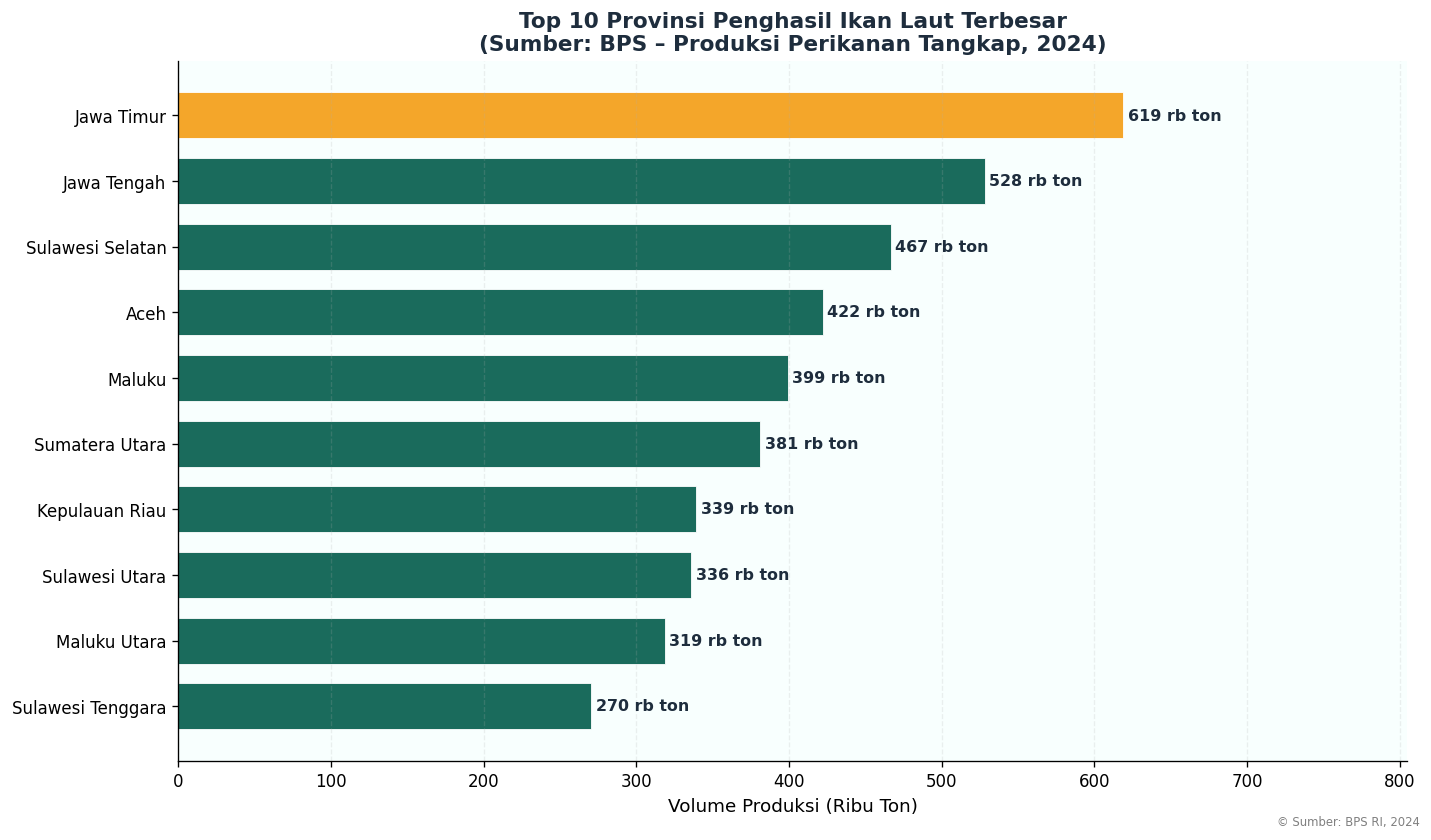

Tersimpan di nama file: grafik1_top10_provinsi_produksi_laut.png


In [41]:
top10 = df_p.nlargest(10, 'Vol_Laut_ton').sort_values('Vol_Laut_ton')

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(top10['Provinsi'], top10['Vol_Laut_ton'] / 1000,
               color=[COLOR_ACCENT if v == top10['Vol_Laut_ton'].max() else COLOR_PRIMARY
                      for v in top10['Vol_Laut_ton']],
               edgecolor='white', linewidth=0.5, height=0.7)
for bar, val in zip(bars, top10['Vol_Laut_ton'] / 1000):
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height() / 2,
            f'{val:,.0f} rb ton', va='center', ha='left', fontsize=9.5,
            fontweight='bold', color=COLOR_DARK)

ax.set_xlabel('Volume Produksi (Ribu Ton)', fontsize=11)
ax.set_title('Top 10 Provinsi Penghasil Ikan Laut Terbesar\n(Sumber: BPS – Produksi Perikanan Tangkap, 2024)',
             fontsize=13, fontweight='bold', color=COLOR_DARK)
ax.set_xlim(0, top10['Vol_Laut_ton'].max() / 1000 * 1.3)
ax.tick_params(axis='y', labelsize=10)
ax.grid(axis='x', alpha=0.2, linestyle='--')
ax.set_facecolor('#f8fffe')
fig.patch.set_facecolor('white')

fig.text(0.99, 0.01, '© Sumber: BPS RI, 2024', ha='right', fontsize=7, color='gray')

plt.tight_layout()
plt.savefig('grafik1_top10_provinsi_produksi_laut.png', dpi=150, bbox_inches='tight')
plt.show()
print("Tersimpan di nama file: grafik1_top10_provinsi_produksi_laut.png")

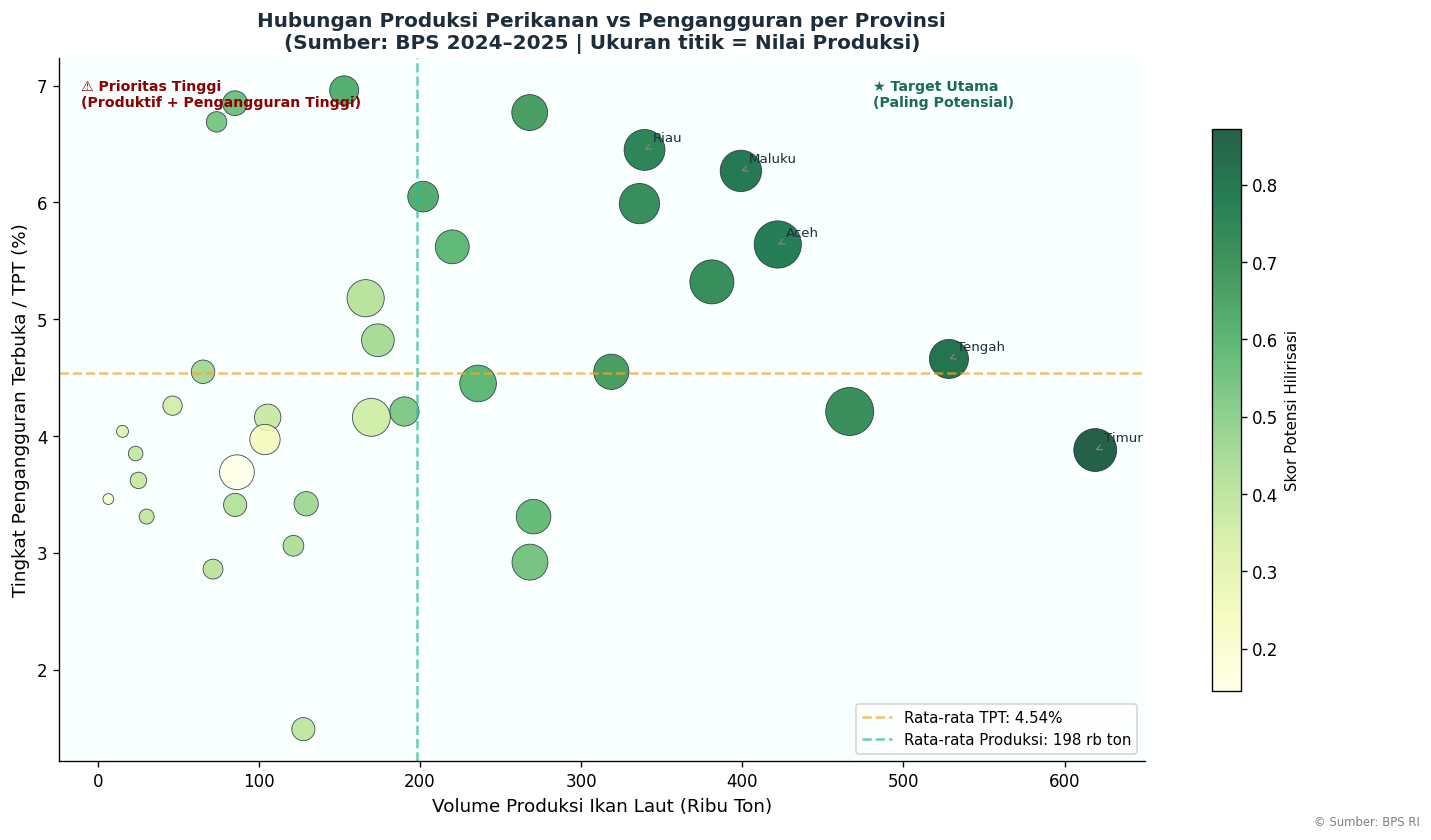

Tersimpan dgn nama file: grafik2_scatter_tpt_vs_produksi.png


In [42]:
df_scatter = df_fe_clean.dropna(subset=['TPT_Ags', 'Vol_Laut_ton']).copy()

fig, ax = plt.subplots(figsize=(12, 7))

scatter = ax.scatter(
    df_scatter['Vol_Laut_ton'] / 1000,
    df_scatter['TPT_Ags'],
    c=df_scatter['skor_potensi'],
    cmap='YlGn',
    s=df_scatter['Nilai_Total_M'] / df_scatter['Nilai_Total_M'].max() * 800 + 30,
    alpha=0.85, edgecolors=COLOR_DARK, linewidths=0.5
)

cbar = plt.colorbar(scatter, ax=ax, shrink=0.8)
cbar.set_label('Skor Potensi Hilirisasi', fontsize=9)

ax.axhline(df_scatter['TPT_Ags'].mean(), color=COLOR_ACCENT,
           linestyle='--', alpha=0.7, linewidth=1.5,
           label=f"Rata-rata TPT: {df_scatter['TPT_Ags'].mean():.2f}%")
ax.axvline(df_scatter['Vol_Laut_ton'].mean() / 1000, color=COLOR_SECONDARY,
           linestyle='--', alpha=0.7, linewidth=1.5,
           label=f"Rata-rata Produksi: {df_scatter['Vol_Laut_ton'].mean()/1000:.0f} rb ton")

ax.text(0.02, 0.97, '⚠ Prioritas Tinggi\n(Produktif + Pengangguran Tinggi)',
        transform=ax.transAxes, fontsize=8.5, va='top',
        color='darkred', fontweight='bold')
ax.text(0.75, 0.97, '★ Target Utama\n(Paling Potensial)',
        transform=ax.transAxes, fontsize=8.5, va='top',
        color=COLOR_PRIMARY, fontweight='bold')

label_provs = df_scatter.nlargest(5, 'skor_potensi')
for _, row in label_provs.iterrows():
    ax.annotate(row['Provinsi'].split()[-1],
                xy=(row['Vol_Laut_ton']/1000, row['TPT_Ags']),
                xytext=(5, 5), textcoords='offset points',
                fontsize=8, color=COLOR_DARK,
                arrowprops=dict(arrowstyle='->', color='gray', lw=0.8))

ax.set_xlabel('Volume Produksi Ikan Laut (Ribu Ton)', fontsize=11)
ax.set_ylabel('Tingkat Pengangguran Terbuka / TPT (%)', fontsize=11)
ax.set_title('Hubungan Produksi Perikanan vs Pengangguran per Provinsi\n'
             '(Sumber: BPS 2024–2025 | Ukuran titik = Nilai Produksi)',
             fontsize=12, fontweight='bold', color=COLOR_DARK)
ax.legend(fontsize=9, loc='lower right')
ax.set_facecolor('#f8fffe')
fig.patch.set_facecolor('white')
fig.text(0.99, 0.01, '© Sumber: BPS RI', ha='right', fontsize=7, color='gray')

plt.tight_layout()
plt.savefig('grafik2_scatter_tpt_vs_produksi.png', dpi=150, bbox_inches='tight')
plt.show()
print("Tersimpan dgn nama file: grafik2_scatter_tpt_vs_produksi.png")

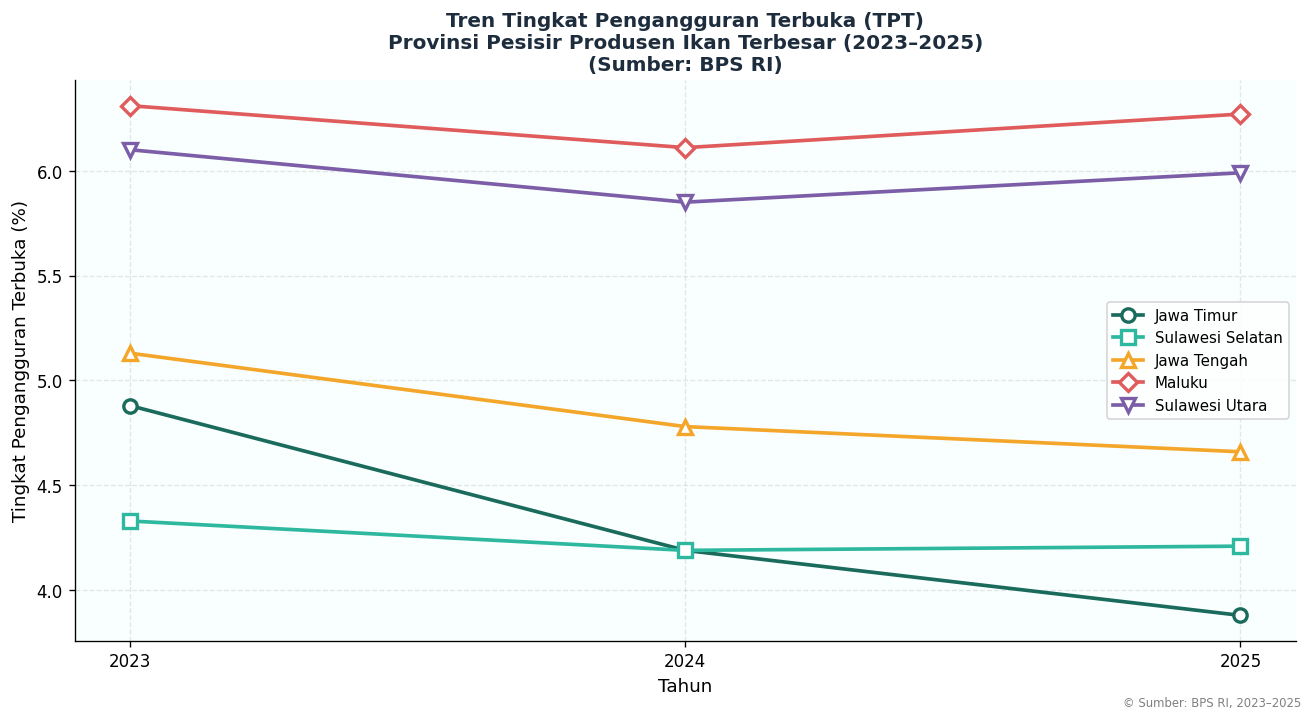

Tersimpan dgnn nama: grafik3_tren_tpt_pesisir.png


In [43]:
target_prov = ['Jawa Timur', 'Sulawesi Selatan', 'Jawa Tengah',
               'Maluku', 'Sulawesi Utara']

def get_prov_tpt(df_kab, year):
    return df_kab[df_kab['is_provinsi'] == True][['wilayah', f'tpt_total_{year}']].copy().rename(
        columns={'wilayah': 'Provinsi', f'tpt_total_{year}': 'tpt'})

tpt23 = get_prov_tpt(df_tpt_23, 2023)
tpt24 = get_prov_tpt(df_tpt_24, 2024)
tpt25p = df_tpt[['prov_key', 'TPT_Ags']].rename(columns={'prov_key': 'Provinsi', 'TPT_Ags': 'tpt'})

tpt23['Tahun'] = 2023
tpt24['Tahun'] = 2024
tpt25p['Tahun'] = 2025

for df_ in [tpt23, tpt24]:
    df_['Provinsi'] = df_['Provinsi'].str.title()

df_tren = pd.concat([tpt23, tpt24, tpt25p], ignore_index=True)
df_tren_filtered = df_tren[df_tren['Provinsi'].isin(target_prov)]

fig, ax = plt.subplots(figsize=(11, 6))

colors_line = [COLOR_PRIMARY, COLOR_SECONDARY, COLOR_ACCENT, '#e05c5c', '#7b5ea7']
markers = ['o', 's', '^', 'D', 'v']

for i, prov in enumerate(target_prov):
    prov_data = df_tren_filtered[df_tren_filtered['Provinsi'] == prov].sort_values('Tahun')
    if len(prov_data) > 0:
        ax.plot(prov_data['Tahun'], prov_data['tpt'],
                marker=markers[i], color=colors_line[i],
                linewidth=2.2, markersize=8, label=prov,
                markerfacecolor='white', markeredgewidth=2)

ax.set_xlabel('Tahun', fontsize=11)
ax.set_ylabel('Tingkat Pengangguran Terbuka (%)', fontsize=11)
ax.set_title('Tren Tingkat Pengangguran Terbuka (TPT)\nProvinsi Pesisir Produsen Ikan Terbesar (2023–2025)\n'
             '(Sumber: BPS RI)',
             fontsize=12, fontweight='bold', color=COLOR_DARK)
ax.set_xticks([2023, 2024, 2025])
ax.legend(fontsize=9, loc='best')
ax.grid(alpha=0.3, linestyle='--')
ax.set_facecolor('#f8fffe')
fig.patch.set_facecolor('white')
fig.text(0.99, 0.01, '© Sumber: BPS RI, 2023–2025', ha='right', fontsize=7, color='gray')

plt.tight_layout()
plt.savefig('grafik3_tren_tpt_pesisir.png', dpi=150, bbox_inches='tight')
plt.show()
print("Tersimpan dgnn nama: grafik3_tren_tpt_pesisir.png")

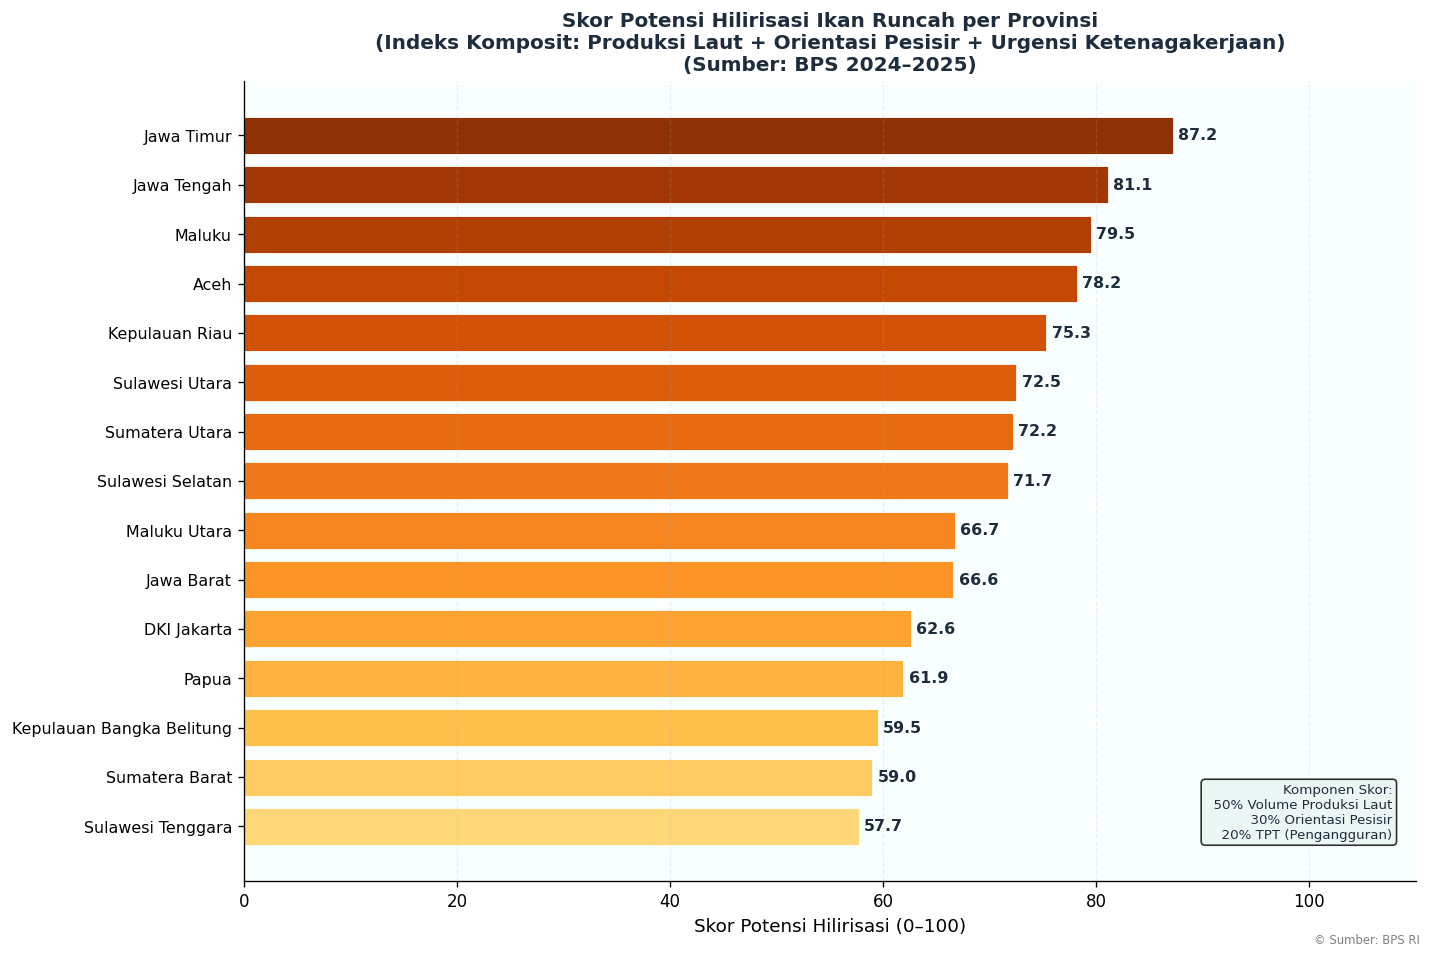

Tersimpan dgn nama: grafik4_skor_potensi_hilirisasi.png


In [45]:
top15_pot = df_fe_clean.nlargest(15, 'skor_potensi').sort_values('skor_potensi')

fig, ax = plt.subplots(figsize=(12, 8))

colors_grad = plt.get_cmap('YlOrBr')(np.linspace(0.3, 0.9, len(top15_pot)))

bars = ax.barh(top15_pot['Provinsi'], top15_pot['skor_potensi_pct'],
               color=colors_grad, edgecolor='white', linewidth=0.5, height=0.75)

for bar, (_, row) in zip(bars, top15_pot.iterrows()):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{row["skor_potensi_pct"]:.1f}',
            va='center', ha='left', fontsize=9.5, fontweight='bold', color=COLOR_DARK)

ax.set_xlabel('Skor Potensi Hilirisasi (0–100)', fontsize=11)
ax.set_title('Skor Potensi Hilirisasi Ikan Runcah per Provinsi\n'
             '(Indeks Komposit: Produksi Laut + Orientasi Pesisir + Urgensi Ketenagakerjaan)\n'
             '(Sumber: BPS 2024–2025)',
             fontsize=12, fontweight='bold', color=COLOR_DARK)
ax.set_xlim(0, 110)
ax.tick_params(axis='y', labelsize=9.5)
ax.grid(axis='x', alpha=0.2, linestyle='--')
ax.set_facecolor('#f8fffe')
fig.patch.set_facecolor('white')
legend_txt = 'Komponen Skor:\n  50% Volume Produksi Laut\n  30% Orientasi Pesisir\n  20% TPT (Pengangguran)'
ax.text(0.98, 0.05, legend_txt, transform=ax.transAxes, fontsize=8,
        ha='right', va='bottom', color=COLOR_DARK,
        bbox=dict(boxstyle='round', facecolor=COLOR_LIGHT, alpha=0.8))
fig.text(0.99, 0.01, '© Sumber: BPS RI', ha='right', fontsize=7, color='gray')

plt.tight_layout()
plt.savefig('grafik4_skor_potensi_hilirisasi.png', dpi=150, bbox_inches='tight')
plt.show()
print("Tersimpan dgn nama: grafik4_skor_potensi_hilirisasi.png")

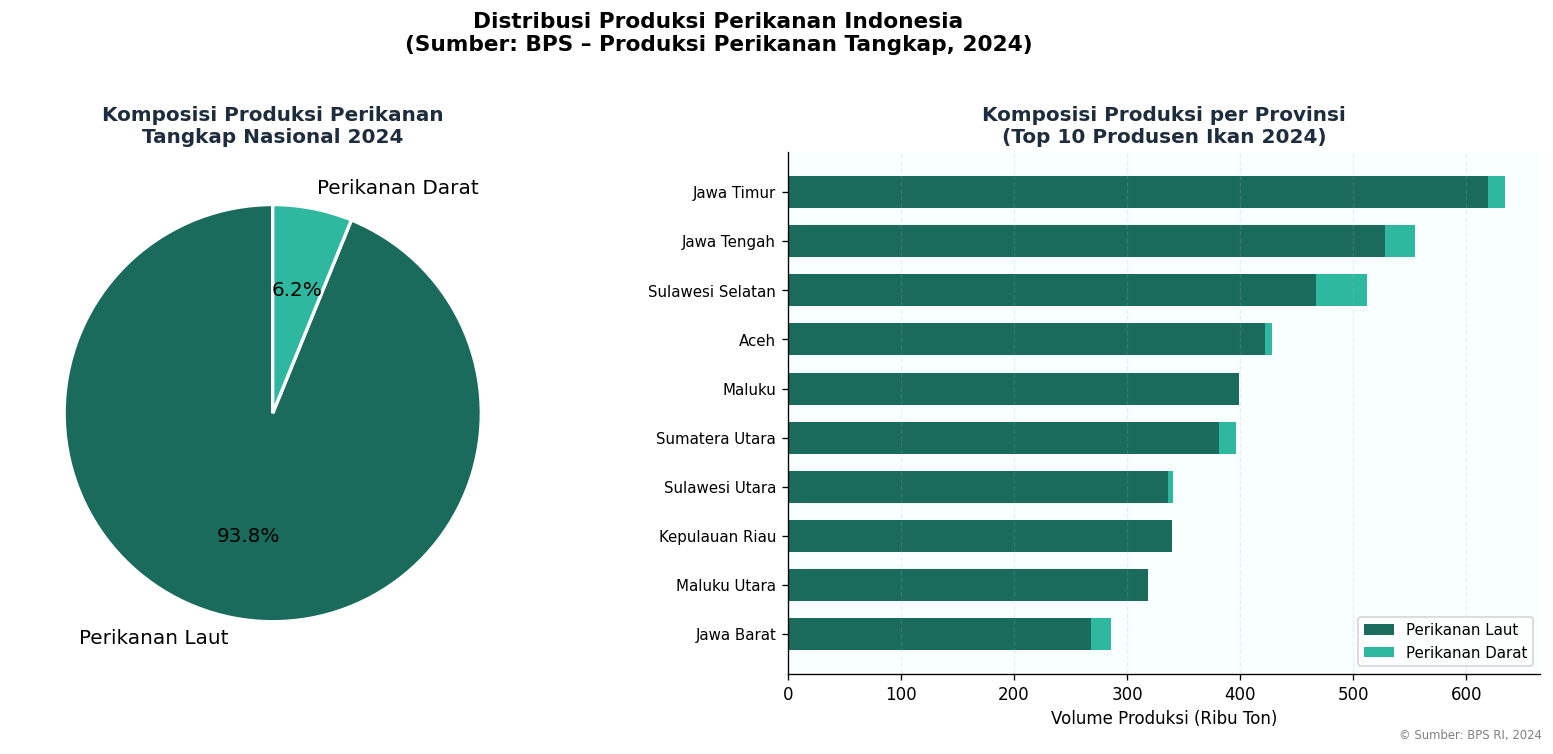

Tersimpan dg nama: grafik5_komposisi_produksi.png


In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

total_laut_n = df_p['Vol_Laut_ton'].sum()
total_darat_n = df_p['Vol_Darat_ton'].sum()

wedge_props = {'linewidth': 2, 'edgecolor': 'white'}
ax1.pie([total_laut_n, total_darat_n],
        labels=['Perikanan Laut', 'Perikanan Darat'],
        colors=[COLOR_PRIMARY, COLOR_SECONDARY],
        autopct='%1.1f%%', startangle=90,
        wedgeprops=wedge_props, textprops={'fontsize': 12})
ax1.set_title('Komposisi Produksi Perikanan\nTangkap Nasional 2024',
              fontsize=12, fontweight='bold', color=COLOR_DARK)

top10_bar = df_p.nlargest(10, 'Vol_Total_ton').copy()
top10_bar = top10_bar.sort_values('Vol_Total_ton')

x = np.arange(len(top10_bar))
width = 0.65

b1 = ax2.barh(x, top10_bar['Vol_Laut_ton'] / 1000,
              color=COLOR_PRIMARY, label='Perikanan Laut', height=width)
b2 = ax2.barh(x, top10_bar['Vol_Darat_ton'] / 1000,
              left=top10_bar['Vol_Laut_ton'] / 1000,
              color=COLOR_SECONDARY, label='Perikanan Darat', height=width)

ax2.set_yticks(x)
ax2.set_yticklabels(top10_bar['Provinsi'], fontsize=9)
ax2.set_xlabel('Volume Produksi (Ribu Ton)', fontsize=10)
ax2.set_title('Komposisi Produksi per Provinsi\n(Top 10 Produsen Ikan 2024)',
              fontsize=12, fontweight='bold', color=COLOR_DARK)
ax2.legend(fontsize=9)
ax2.grid(axis='x', alpha=0.2, linestyle='--')
ax2.set_facecolor('#f8fffe')

fig.suptitle('Distribusi Produksi Perikanan Indonesia\n'
             '(Sumber: BPS – Produksi Perikanan Tangkap, 2024)',
             fontsize=13, fontweight='bold', y=1.02)
fig.patch.set_facecolor('white')
fig.text(0.99, 0.01, '© Sumber: BPS RI, 2024', ha='right', fontsize=7, color='gray')

plt.tight_layout()
plt.savefig('grafik5_komposisi_produksi.png', dpi=150, bbox_inches='tight')
plt.show()
print("Tersimpan dg nama: grafik5_komposisi_produksi.png")

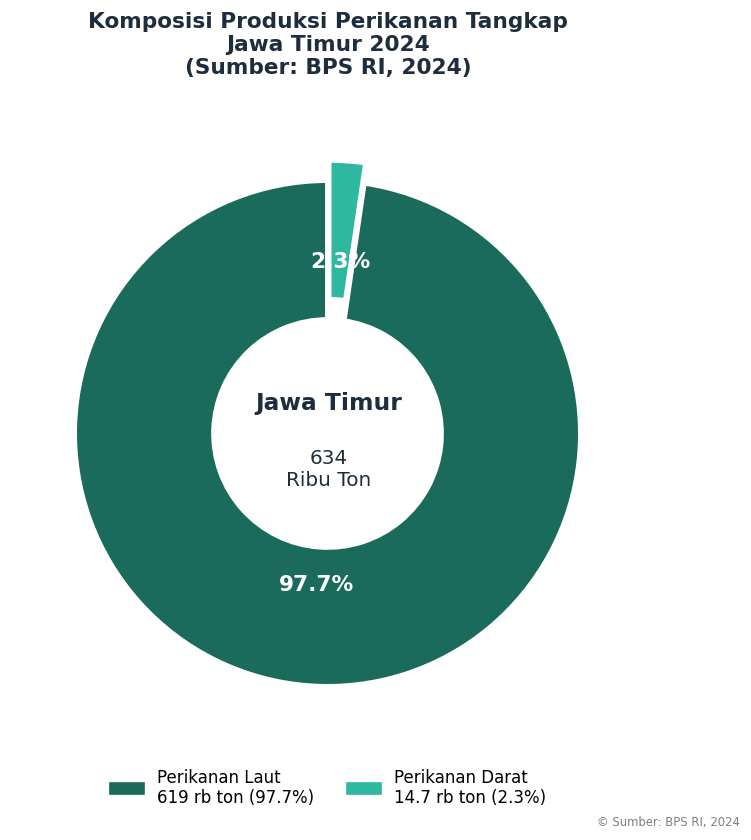

Tersimpan dg nama: grafik_jatim_donut.png


In [48]:
jatim = df_p[df_p['Provinsi'] == 'Jawa Timur'].iloc[0]
vol_laut  = jatim['Vol_Laut_ton']
vol_darat = jatim['Vol_Darat_ton']
total     = vol_laut + vol_darat

fig, ax = plt.subplots(figsize=(7, 7))

sizes  = [vol_laut, vol_darat]
labels = ['Perikanan Laut', 'Perikanan Darat']
colors_d = ['#1a6b5c', '#2eb8a0']
explode  = (0.04, 0.04)

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=None,
    colors=colors_d,
    autopct='%1.1f%%',
    startangle=90,
    explode=explode,
    wedgeprops={'linewidth': 3, 'edgecolor': 'white', 'width': 0.55},  # <-- bikin donut
    textprops={'fontsize': 13, 'fontweight': 'bold', 'color': 'white'}
)

ax.text(0, 0.08, 'Jawa Timur', ha='center', va='center',
        fontsize=14, fontweight='bold', color='#1e2d3d')
ax.text(0, -0.18, f'{total/1000:,.0f}\nRibu Ton', ha='center', va='center',
        fontsize=12, color='#1e2d3d')

legend_labels = [
    f'Perikanan Laut\n{vol_laut/1000:,.0f} rb ton ({vol_laut/total*100:.1f}%)',
    f'Perikanan Darat\n{vol_darat/1000:,.1f} rb ton ({vol_darat/total*100:.1f}%)'
]
patches = [
    mpatches.Patch(color=colors_d[0], label=legend_labels[0]),
    mpatches.Patch(color=colors_d[1], label=legend_labels[1])
]
ax.legend(handles=patches, loc='lower center', bbox_to_anchor=(0.5, -0.13),
          fontsize=10, frameon=False, ncol=2)

ax.set_title(
    'Komposisi Produksi Perikanan Tangkap\nJawa Timur 2024\n'
    '(Sumber: BPS RI, 2024)',
    fontsize=13, fontweight='bold', color='#1e2d3d', pad=20
)

fig.patch.set_facecolor('white')
fig.text(0.99, 0.01, '© Sumber: BPS RI, 2024', ha='right', fontsize=7, color='gray')

plt.tight_layout()
plt.savefig('grafik_jatim_donut.png', dpi=150, bbox_inches='tight')
plt.show()
print("Tersimpan dg nama: grafik_jatim_donut.png")

BAGIAN 8: Machine Learning Modeling & Comparison

ML MODEL 1: K-MEANS CLUSTERING
Tujuan: Klasterisasi Provinsi Pesisir


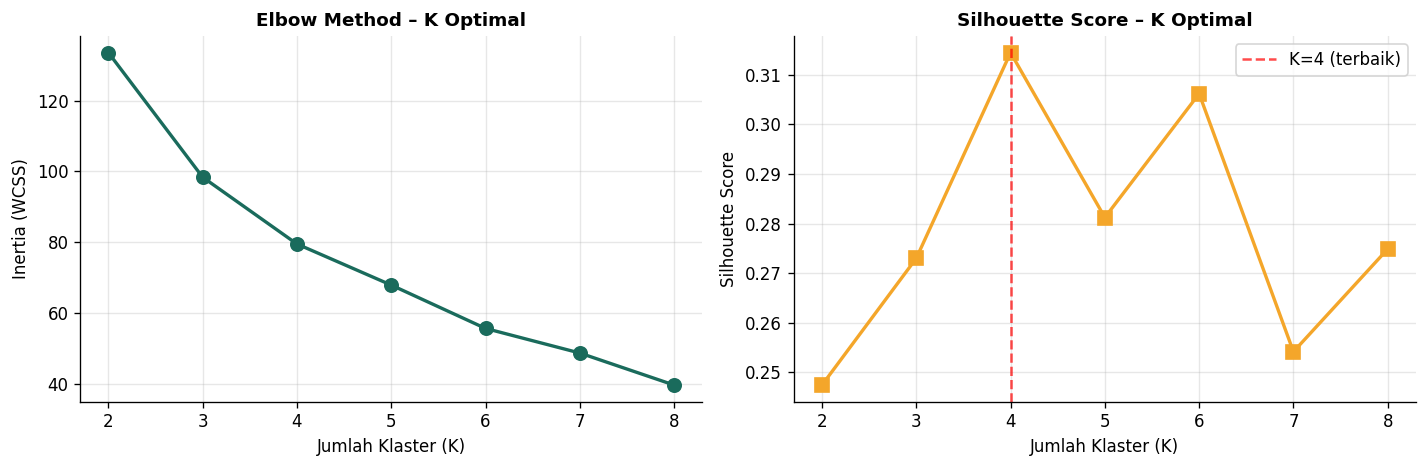


 Hasil Evaluasi K:
   K=2: Silhouette = 0.2474
   K=3: Silhouette = 0.2730
   K=4: Silhouette = 0.3145 ← TERBAIK
   K=5: Silhouette = 0.2812
   K=6: Silhouette = 0.3062
   K=7: Silhouette = 0.2542
   K=8: Silhouette = 0.2749

 K optimal: 4


In [49]:
print("=" * 55)
print("ML MODEL 1: K-MEANS CLUSTERING")
print("Tujuan: Klasterisasi Provinsi Pesisir")
print("=" * 55)

features_cluster = ['Vol_Laut_ton', 'rasio_laut', 'harga_per_ton_rb', 'TPT_Ags', 'TPAK_Ags']
df_cl = df_fe_clean.dropna(subset=features_cluster).copy()

X_cl = df_cl[features_cluster].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cl)

inertias = []
silhouettes = []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(K_range, inertias, 'o-', color=COLOR_PRIMARY, linewidth=2, markersize=8)
ax1.set_xlabel('Jumlah Klaster (K)', fontsize=10)
ax1.set_ylabel('Inertia (WCSS)', fontsize=10)
ax1.set_title('Elbow Method – K Optimal', fontsize=11, fontweight='bold')
ax1.grid(alpha=0.3)

ax2.plot(K_range, silhouettes, 's-', color=COLOR_ACCENT, linewidth=2, markersize=8)
ax2.set_xlabel('Jumlah Klaster (K)', fontsize=10)
ax2.set_ylabel('Silhouette Score', fontsize=10)
ax2.set_title('Silhouette Score – K Optimal', fontsize=11, fontweight='bold')
ax2.grid(alpha=0.3)

best_k = list(K_range)[np.argmax(silhouettes)]
ax2.axvline(best_k, color='red', linestyle='--', alpha=0.7, label=f'K={best_k} (terbaik)')
ax2.legend()

plt.tight_layout()
plt.savefig('ml1_elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n Hasil Evaluasi K:")
for k, sil in zip(K_range, silhouettes):
    marker = ' ← TERBAIK' if k == best_k else ''
    print(f"   K={k}: Silhouette = {sil:.4f}{marker}")
print(f"\n K optimal: {best_k}")

PROFIL KLASTER:


,Vol_Laut_ton,rasio_laut,harga_per_ton_rb,TPT_Ags,TPAK_Ags
Klaster,,,,,
0,104723.69,0.80,38.24,4.27,69.34
1,278649.94,0.98,29.83,5.84,67.58
2,573655.90,0.97,17.29,4.27,74.17
3,111663.90,0.95,26.35,3.28,72.54


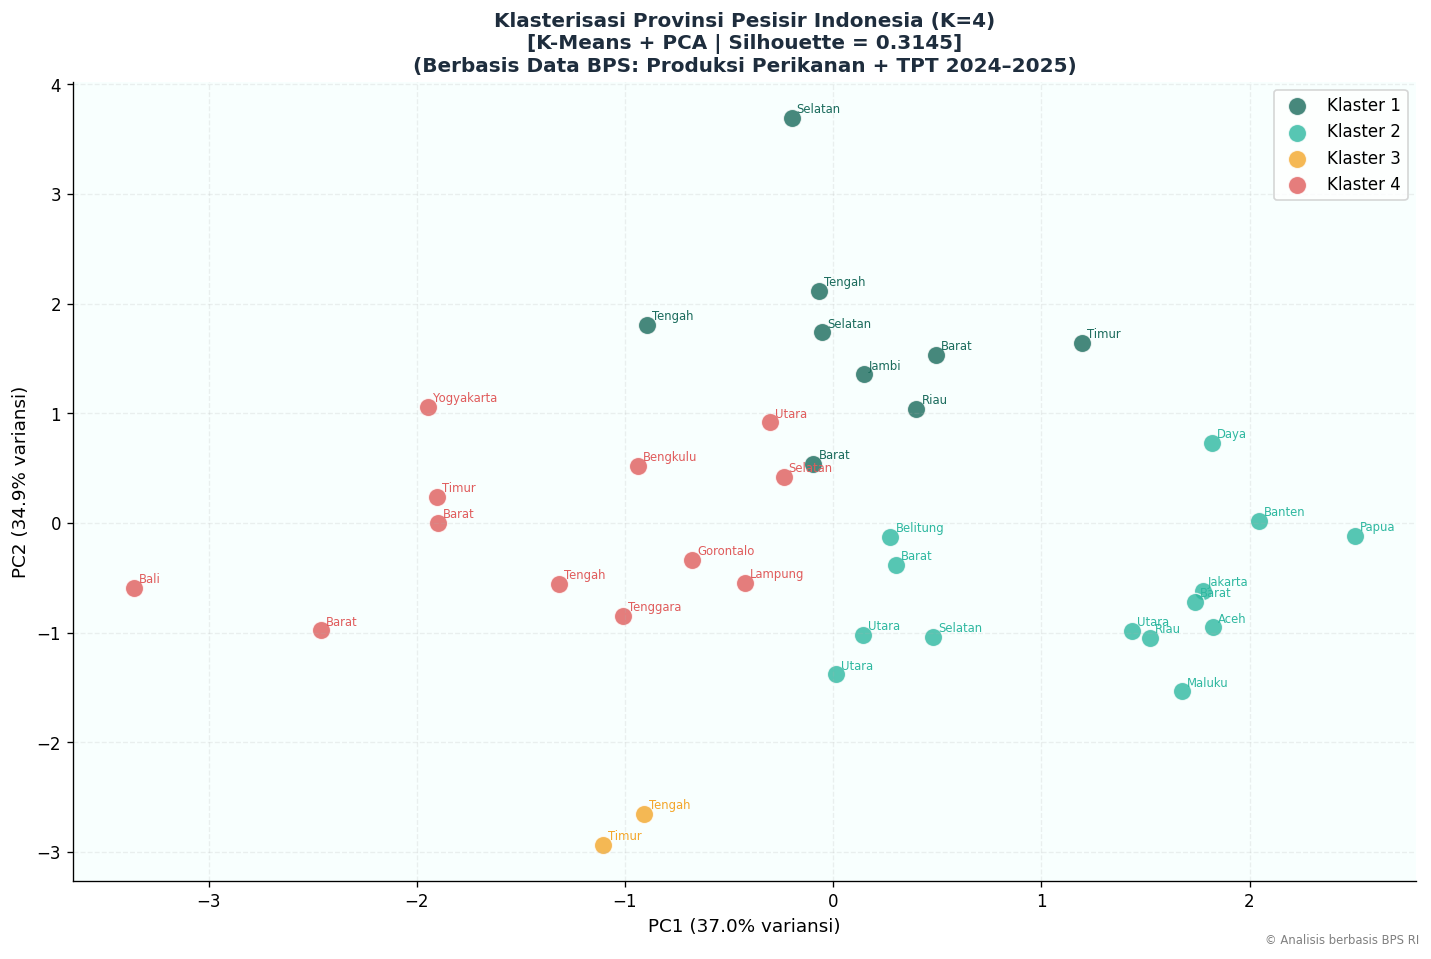

Tersimpan dg nama: ml2_kmeans_cluster_pca.png


In [51]:
BEST_K = best_k
km_final = KMeans(n_clusters=BEST_K, random_state=42, n_init=20)
df_cl['Klaster'] = km_final.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
df_cl['PCA1'] = X_pca[:, 0]
df_cl['PCA2'] = X_pca[:, 1]

klaster_summary = df_cl.groupby('Klaster')[features_cluster].mean()
print("PROFIL KLASTER:")
display(klaster_summary.round(2))

colors_cl = [COLOR_PRIMARY, COLOR_SECONDARY, COLOR_ACCENT, '#e05c5c', '#7b5ea7', '#3a87c5']
klaster_names = [f'Klaster {k+1}' for k in range(BEST_K)]

fig, ax = plt.subplots(figsize=(12, 8))

for k in range(BEST_K):
    mask = df_cl['Klaster'] == k
    ax.scatter(df_cl.loc[mask, 'PCA1'], df_cl.loc[mask, 'PCA2'],
               c=colors_cl[k], s=120, label=klaster_names[k],
               alpha=0.8, edgecolors='white', linewidths=0.8)
    for _, row in df_cl[mask].iterrows():
        ax.annotate(row['Provinsi'].split()[-1],
                    xy=(row['PCA1'], row['PCA2']),
                    xytext=(3, 3), textcoords='offset points',
                    fontsize=7, color=colors_cl[k])

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variansi)', fontsize=11)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variansi)', fontsize=11)
ax.set_title(f'Klasterisasi Provinsi Pesisir Indonesia (K={BEST_K})\n'
             f'[K-Means + PCA | Silhouette = {silhouettes[best_k-2]:.4f}]\n'
             '(Berbasis Data BPS: Produksi Perikanan + TPT 2024–2025)',
             fontsize=12, fontweight='bold', color=COLOR_DARK)
ax.legend(fontsize=10, loc='best')
ax.grid(alpha=0.2, linestyle='--')
ax.set_facecolor('#f8fffe')
fig.patch.set_facecolor('white')
fig.text(0.99, 0.01, '© Analisis berbasis BPS RI', ha='right', fontsize=7, color='gray')

plt.tight_layout()
plt.savefig('ml2_kmeans_cluster_pca.png', dpi=150, bbox_inches='tight')
plt.show()
print("Tersimpan dg nama: ml2_kmeans_cluster_pca.png")

In [52]:
print("=" * 55)
print("ML MODEL 2: REGRESI (Prediksi Nilai Produksi)")
print("=" * 55)

features_reg = ['Vol_Laut_ton', 'rasio_laut', 'TPT_Ags', 'TPAK_Ags', 'is_pesisir']
target_reg = 'Nilai_Total_M'

df_reg = df_fe_clean.dropna(subset=features_reg + [target_reg]).copy()

X = df_reg[features_reg].values
y = df_reg[target_reg].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

print(f"  Train: {len(X_train)} sampel | Test: {len(X_test)} sampel")

sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s  = sc.transform(X_test)

models = {
    'Linear Regression'       : LinearRegression(),
    'Ridge Regression'        : Ridge(alpha=1.0),
    'Lasso Regression'        : Lasso(alpha=0.1),
    'Random Forest'           : RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting'       : GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)

    mse  = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_test, y_pred)
    r2   = r2_score(y_test, y_pred)

    cv_r2 = cross_val_score(model, sc.fit_transform(X), y, cv=5, scoring='r2').mean()

    results.append({'Model': name, 'RMSE': rmse, 'MAE': mae, 'R²': r2, 'CV R²': cv_r2})
    trained_models[name] = model
    print(f"  [{name}] R²={r2:.4f} | RMSE={rmse:,.1f} | CV R²={cv_r2:.4f}")

df_results = pd.DataFrame(results).sort_values('R²', ascending=False)
print("\n Perbandingan Model:")
display(df_results)

ML MODEL 2: REGRESI (Prediksi Nilai Produksi)
  Train: 27 sampel | Test: 10 sampel
  [Linear Regression] R²=0.8831 | RMSE=1,506.5 | CV R²=0.7065
  [Ridge Regression] R²=0.8691 | RMSE=1,594.4 | CV R²=0.7367
  [Lasso Regression] R²=0.8831 | RMSE=1,506.6 | CV R²=0.7066
  [Random Forest] R²=0.8671 | RMSE=1,606.3 | CV R²=0.7268
  [Gradient Boosting] R²=0.7984 | RMSE=1,978.8 | CV R²=0.7176

 Perbandingan Model:


,Model,RMSE,MAE,R²,CV R²
0,Linear Regression,1506.510156,1287.628795,0.883118,0.706513
2,Lasso Regression,1506.575236,1287.625539,0.883108,0.706582
1,Ridge Regression,1594.387432,1318.441114,0.869085,0.736673
3,Random Forest,1606.332202,1227.513189,0.867116,0.726826
4,Gradient Boosting,1978.752610,1405.506618,0.798356,0.717636



 Model Terbaik n ter sesuai: Linear Regression (R² = 0.8831)


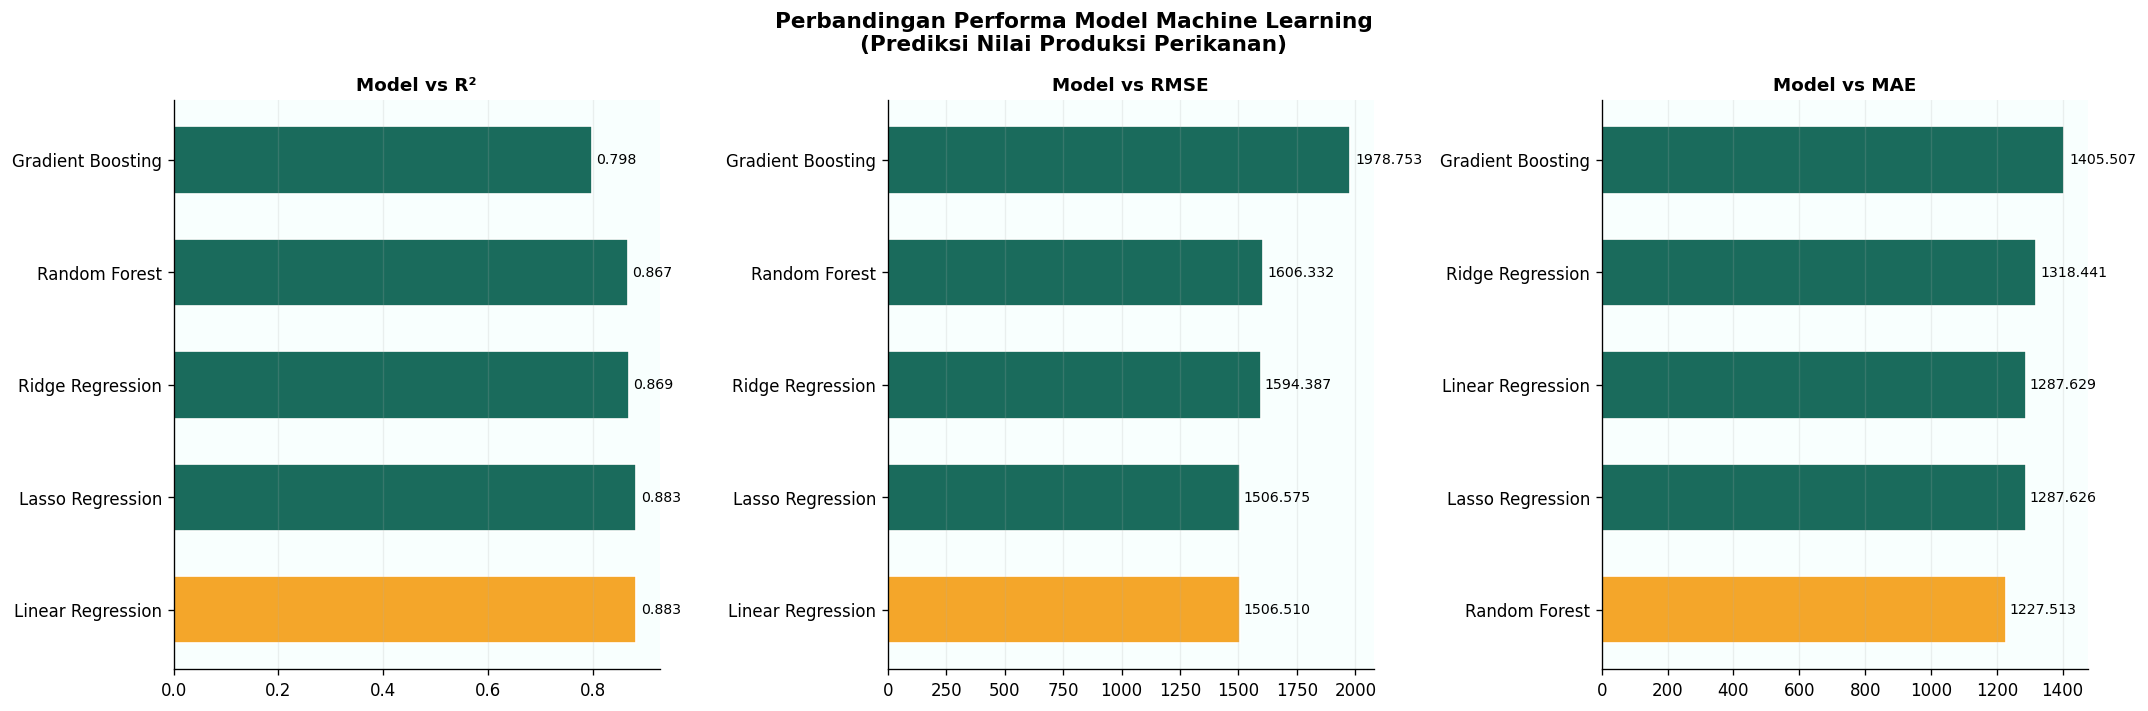

Tersimpan dg nama: ml3_model_comparison.png


In [54]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Perbandingan Performa Model Machine Learning\n'
             '(Prediksi Nilai Produksi Perikanan)',
             fontsize=13, fontweight='bold')

metrics = ['R²', 'RMSE', 'MAE']
ascending = [False, True, True]

for i, (metric, asc) in enumerate(zip(metrics, ascending)):
    df_sort = df_results.sort_values(metric, ascending=asc)
    colors_m = [COLOR_ACCENT if j == 0 else COLOR_PRIMARY for j in range(len(df_sort))]

    axes[i].barh(df_sort['Model'], df_sort[metric],
                  color=colors_m, edgecolor='white', height=0.6)

    for bar, val in zip(axes[i].patches, df_sort[metric]):
        axes[i].text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2,
                      f'{val:.3f}', va='center', ha='left', fontsize=8.5)

    axes[i].set_title(f'Model vs {metric}', fontsize=11, fontweight='bold')
    axes[i].grid(axis='x', alpha=0.2)
    axes[i].set_facecolor('#f8fffe')

best_model_name = df_results.iloc[0]['Model']
best_r2 = df_results.iloc[0]['R²']
print(f"\n Model Terbaik n ter sesuai: {best_model_name} (R² = {best_r2:.4f})")

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.savefig('ml3_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Tersimpan dg nama: ml3_model_comparison.png")

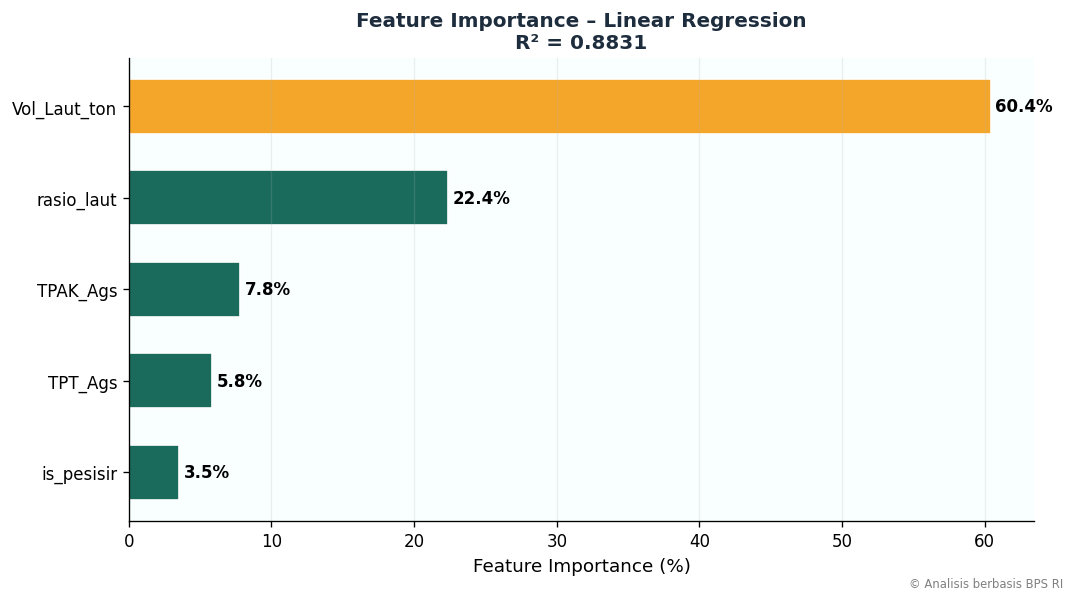

Tersimpan dg nama: ml4_feature_importance.png

 Fitur Paling Berpengaruh:


,Fitur,Importance (%)
0,Vol_Laut_ton,60.442200
1,rasio_laut,22.371714
3,TPAK_Ags,7.810266
2,TPT_Ags,5.836759
4,is_pesisir,3.539062


In [55]:
best_model = trained_models[best_model_name]

if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
else:
    importances = np.abs(best_model.coef_)

imp_pct = importances / importances.sum() * 100

df_imp = pd.DataFrame({
    'Fitur': features_reg,
    'Importance (%)': imp_pct
}).sort_values('Importance (%)', ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))

colors_imp = [COLOR_ACCENT if v == df_imp['Importance (%)'].max() else COLOR_PRIMARY
              for v in df_imp['Importance (%)']]

bars = ax.barh(df_imp['Fitur'], df_imp['Importance (%)'],
               color=colors_imp, edgecolor='white', height=0.6)

for bar, val in zip(bars, df_imp['Importance (%)']):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%', va='center', ha='left', fontsize=10, fontweight='bold')

ax.set_xlabel('Feature Importance (%)', fontsize=11)
ax.set_title(f'Feature Importance – {best_model_name}\n'
             f'R² = {best_r2:.4f}',
             fontsize=12, fontweight='bold', color=COLOR_DARK)
ax.grid(axis='x', alpha=0.2)
ax.set_facecolor('#f8fffe')
fig.patch.set_facecolor('white')
fig.text(0.99, 0.01, '© Analisis berbasis BPS RI', ha='right', fontsize=7, color='gray')

plt.tight_layout()
plt.savefig('ml4_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("Tersimpan dg nama: ml4_feature_importance.png")
print("\n Fitur Paling Berpengaruh:")
display(df_imp.sort_values('Importance (%)', ascending=False))

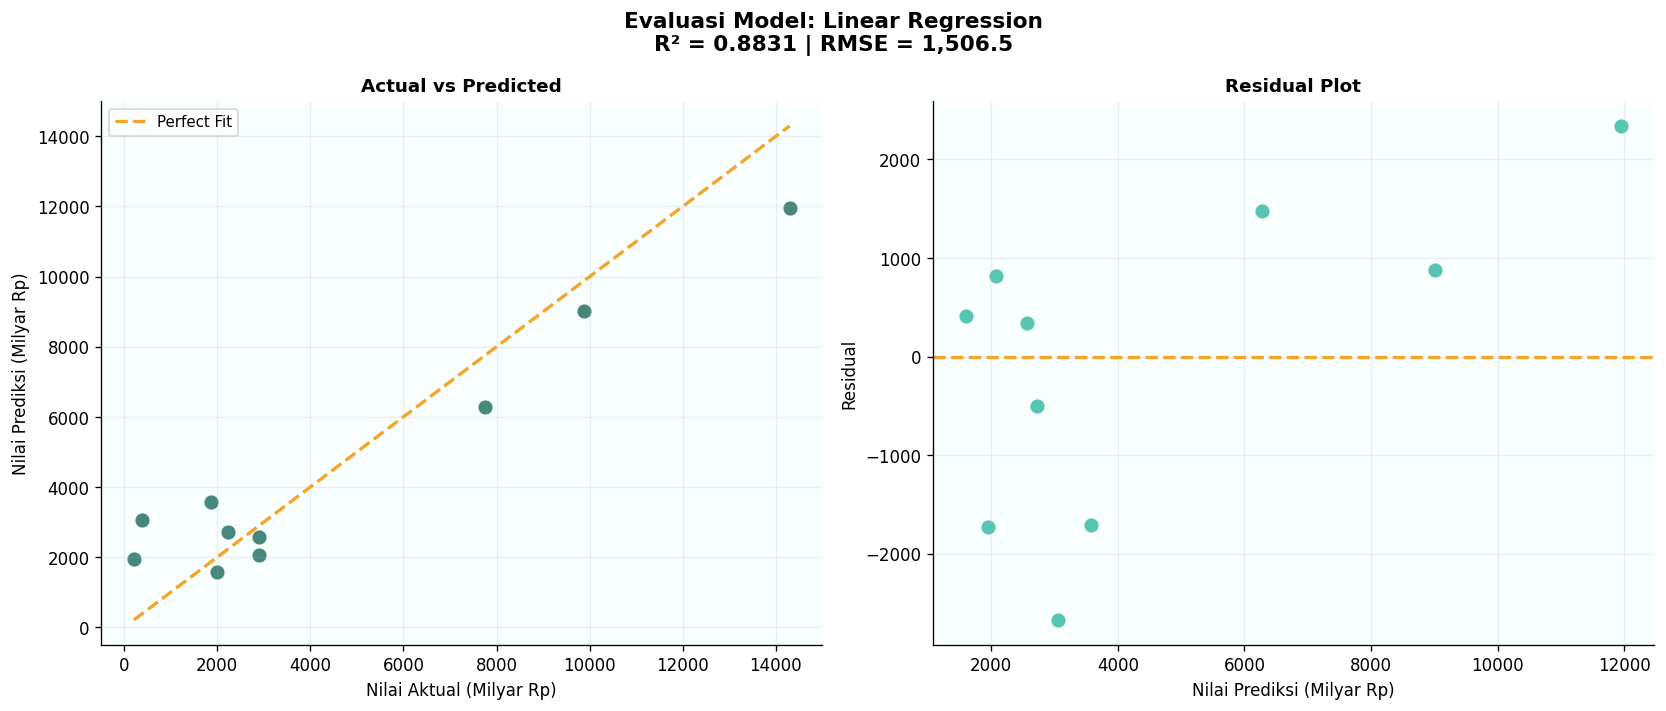

Tersimpan ml5_actual_vs_predicted.png


In [56]:
y_pred_best = best_model.predict(X_test_s)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f'Evaluasi Model: {best_model_name}\n'
             f'R² = {best_r2:.4f} | RMSE = {df_results.iloc[0]["RMSE"]:,.1f}',
             fontsize=13, fontweight='bold')

ax1 = axes[0]
ax1.scatter(y_test, y_pred_best, c=COLOR_PRIMARY, alpha=0.8, s=80,
             edgecolors='white', linewidths=0.5)

min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
ax1.plot([min_val, max_val], [min_val, max_val],
          '--', color=COLOR_ACCENT, linewidth=2, label='Perfect Fit')
ax1.set_xlabel('Nilai Aktual (Milyar Rp)', fontsize=10)
ax1.set_ylabel('Nilai Prediksi (Milyar Rp)', fontsize=10)
ax1.set_title('Actual vs Predicted', fontsize=11, fontweight='bold')
ax1.legend(fontsize=9)
ax1.grid(alpha=0.2)
ax1.set_facecolor('#f8fffe')

ax2 = axes[1]
residuals = y_test - y_pred_best
ax2.scatter(y_pred_best, residuals, c=COLOR_SECONDARY, alpha=0.8, s=80,
             edgecolors='white', linewidths=0.5)
ax2.axhline(0, color=COLOR_ACCENT, linestyle='--', linewidth=2)
ax2.set_xlabel('Nilai Prediksi (Milyar Rp)', fontsize=10)
ax2.set_ylabel('Residual', fontsize=10)
ax2.set_title('Residual Plot', fontsize=11, fontweight='bold')
ax2.grid(alpha=0.2)
ax2.set_facecolor('#f8fffe')

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.savefig('ml5_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()
print("Tersimpan ml5_actual_vs_predicted.png")

BAGIAN 9: Ringkasan Hasil & Rekomendasi

In [57]:
print("=" * 65)
print("  RINGKASAN HASIL ANALISIS")
print("  Optimalisasi Hammer Mill – Hilirisasi Ikan Runcah Pesisir")
print("=" * 65)

print("\n DATA PRODUKSI PERIKANAN (BPS 2024):")
print(f"   Total Produksi Nasional   : {df_p['Vol_Total_ton'].sum():>12,.0f} ton")
print(f"   Total Produksi Laut       : {df_p['Vol_Laut_ton'].sum():>12,.0f} ton")
print(f"   Total Nilai Produksi      : Rp {df_p['Nilai_Total_M'].sum():>12,.1f} Milyar")
print(f"   Provinsi Penghasil Ikan   : {len(df_p)} provinsi")

print("\n KONDISI KETENAGAKERJAAN (BPS 2025):")
print(f"   TPT Nasional (Agustus)    : {df_tpt_prov['Tingkat Pengangguran Terbuka (TPT) - Agustus'].iloc[-1]:.2f}%")
print(f"   TPAK Nasional (Agustus)   : {df_tpt_prov['Tingkat Partisipasi Angkatan Kerja (TPAK) - Agustus'].iloc[-1]:.2f}%")
print(f"   Provinsi TPT tertinggi    : {df_tpt.nlargest(1,'TPT_Ags')['Provinsi'].values[0]} ({df_tpt['TPT_Ags'].max():.2f}%)")
print(f"   Provinsi TPAK tertinggi   : {df_tpt.nlargest(1,'TPAK_Ags')['Provinsi'].values[0]} ({df_tpt['TPAK_Ags'].max():.2f}%)")

print("\n HASIL MACHINE LEARNING:")
print(f"   Model Terbaik (Regresi)   : {best_model_name}")
print(f"   R² Score                  : {best_r2:.4f}")
print(f"   RMSE                      : {df_results.iloc[0]['RMSE']:,.1f} Milyar Rp")
print(f"   Klaster Provinsi (K-Means): {BEST_K} klaster")
print(f"   Silhouette Score           : {silhouettes[BEST_K-2]:.4f}")

print("\n TOPP 5 PROVINSI PRIORITAS HILIRISASI:")
top5 = df_fe_clean.nlargest(5, 'skor_potensi')[['Provinsi', 'Vol_Laut_ton', 'TPT_Ags', 'skor_potensi_pct']]
for i, (_, row) in enumerate(top5.iterrows(), 1):
    print(f"   {i}. {row['Provinsi']:25s} | Produksi: {row['Vol_Laut_ton']/1000:5.0f} rb ton | TPT: {row['TPT_Ags']:.1f}% | Skor: {row['skor_potensi_pct']:.0f}/100")

print("\n FILE OUTPUT YANG DIHASILKAN:")
outputs = [
    'grafik1_top10_provinsi_produksi_laut.png',
    'grafik2_scatter_tpt_vs_produksi.png',
    'grafik3_tren_tpt_pesisir.png',
    'grafik4_skor_potensi_hilirisasi.png',
    'grafik5_komposisi_produksi.png',
    'ml1_elbow_silhouette.png',
    'ml2_kmeans_cluster_pca.png',
    'ml3_model_comparison.png',
    'ml4_feature_importance.png',
    'ml5_actual_vs_predicted.png',
    'output_outlier_boxplot.png'
]
for f in outputs:
    print(f" {f}")

print("\n SUMBER DATA:")
print("   BPS RI – https://www.bps.go.id")
print("   [1] Volume & Nilai Produksi Perikanan Tangkap Menurut Provinsi, 2024")
print("   [2] Volume & Nilai Produksi Perikanan Tangkap di Perairan Darat, 2024")
print("   [3] Tingkat Pengangguran Terbuka & TPAK Menurut Provinsi, 2025")
print("   [4] TPT Menurut Jenis Kelamin & Kabupaten/Kota, 2023–2025")

  RINGKASAN HASIL ANALISIS
  Optimalisasi Hammer Mill – Hilirisasi Ikan Runcah Pesisir

 DATA PRODUKSI PERIKANAN (BPS 2024):
   Total Produksi Nasional   :    7,811,614 ton
   Total Produksi Laut       :    7,330,891 ton
   Total Nilai Produksi      : Rp    218,823.4 Milyar
   Provinsi Penghasil Ikan   : 38 provinsi

 KONDISI KETENAGAKERJAAN (BPS 2025):
   TPT Nasional (Agustus)    : 4.85%
   TPAK Nasional (Agustus)   : 70.59%
   Provinsi TPT tertinggi    : Papua (6.96%)
   Provinsi TPAK tertinggi   : Papua Pegunungan (90.66%)

 HASIL MACHINE LEARNING:
   Model Terbaik (Regresi)   : Linear Regression
   R² Score                  : 0.8831
   RMSE                      : 1,506.5 Milyar Rp
   Klaster Provinsi (K-Means): 4 klaster
   Silhouette Score           : 0.3145

 TOPP 5 PROVINSI PRIORITAS HILIRISASI:
   1. Jawa Timur                | Produksi:   619 rb ton | TPT: 3.9% | Skor: 87/100
   2. Jawa Tengah               | Produksi:   528 rb ton | TPT: 4.7% | Skor: 81/100
   3. Maluku     

In [58]:
export_cols = ['Provinsi', 'Vol_Laut_ton', 'Vol_Darat_ton', 'Vol_Total_ton',
               'Nilai_Total_M', 'rasio_laut', 'harga_per_ton_rb',
               'TPT_Ags', 'TPAK_Ags', 'is_pesisir', 'skor_potensi_pct']

if 'Klaster' in df_cl.columns:
    df_fe_clean = df_fe_clean.merge(
        df_cl[['Provinsi', 'Klaster']], on='Provinsi', how='left')
    export_cols.append('Klaster')

df_export = df_fe_clean[export_cols].copy()
df_export = df_export.sort_values('skor_potensi_pct', ascending=False)
df_export.to_csv('hasil_analisis_hilirisasi_ikan_runcah.csv', index=False, encoding='utf-8-sig')

print("File CSV tersimpan: hasil_analisis_hilirisasi_ikan_runcah.csv")
print(f"   Berisi {len(df_export)} provinsi dengan {len(export_cols)} kolom")
display(df_export.head(10))

File CSV tersimpan: hasil_analisis_hilirisasi_ikan_runcah.csv
   Berisi 37 provinsi dengan 12 kolom


,Provinsi,Vol_Laut_ton,Vol_Darat_ton,Vol_Total_ton,Nilai_Total_M,rasio_laut,harga_per_ton_rb,TPT_Ags,TPAK_Ags,is_pesisir,skor_potensi_pct,Klaster
14,Jawa Timur,619052.665,14665.925,633718.590,11297.737910,0.976857,17.827689,3.88,73.98,1,87.2,2
12,Jawa Tengah,528259.134,25922.003,554181.137,9284.586124,0.953225,16.753703,4.66,74.36,1,81.1,2
30,Maluku,399142.651,0.000,399142.651,10476.378375,1.000000,26.247203,6.27,66.66,1,79.5,1
0,Aceh,422025.289,5614.432,427639.721,13799.502597,0.986871,32.268992,5.64,65.32,1,78.2,1
9,Kepulauan Riau,339329.306,0.000,339329.306,10203.661036,1.000000,30.070085,6.45,68.23,1,75.3,1
24,Sulawesi Utara,336186.306,4725.922,340912.228,9882.365147,0.986137,28.988004,5.99,67.21,1,72.5,1
1,Sumatera Utara,381128.980,14689.686,395818.666,11912.824045,0.962888,30.096671,5.32,72.29,1,72.2,1
26,Sulawesi Selatan,466673.235,45811.494,512484.729,14294.289156,0.910609,27.892127,4.21,67.65,1,71.7,1
31,Maluku Utara,318734.261,0.000,318734.261,7449.182227,1.000000,23.371137,4.55,69.57,1,66.7,1
11,Jawa Barat,268077.413,17858.979,285936.392,7735.374205,0.937542,27.052780,6.77,66.99,1,66.6,1


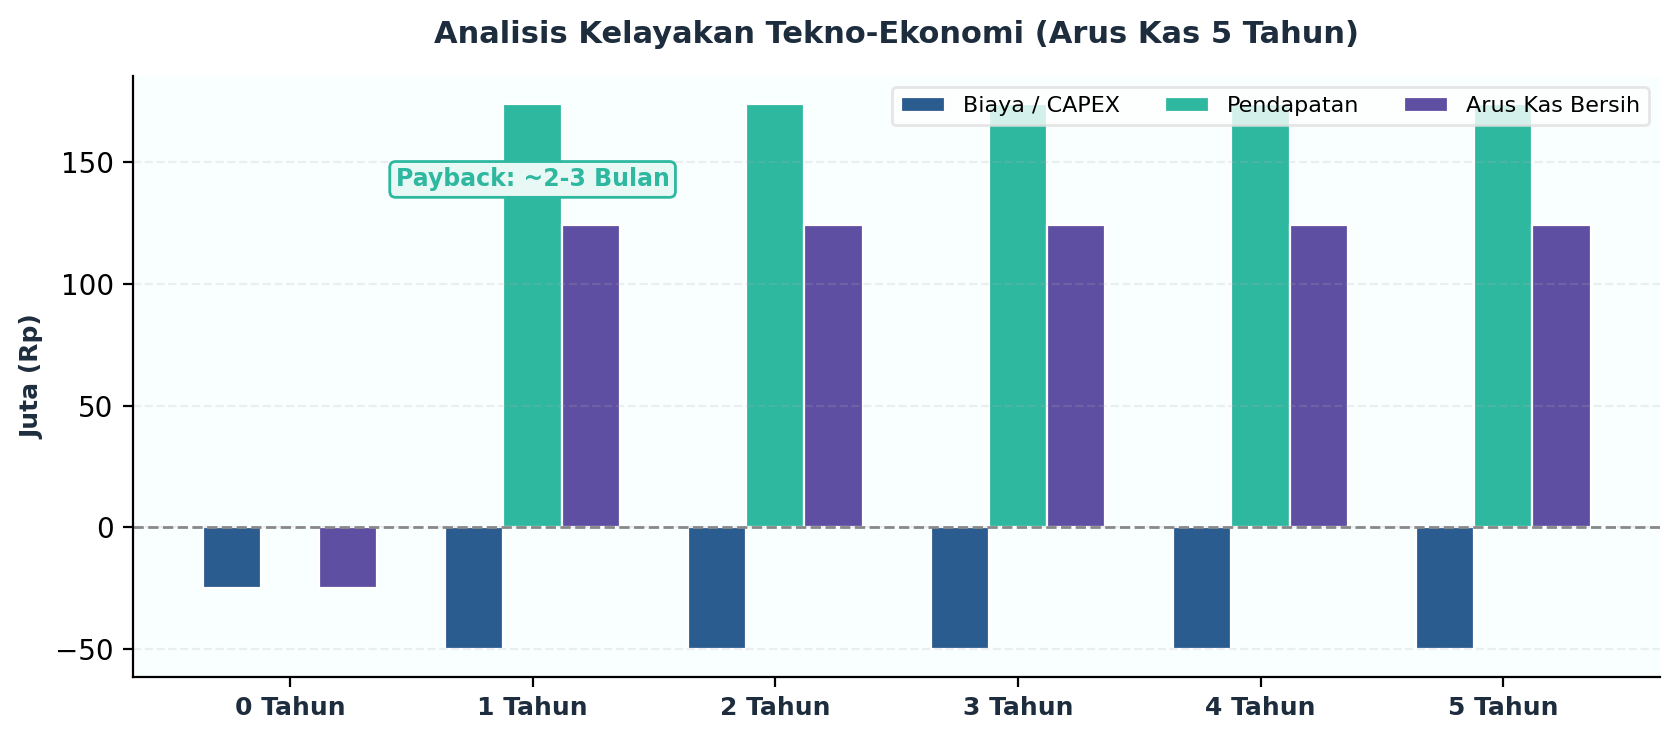

In [60]:
#bagian ini hanya untuk membuat graph kebutuhan visualisasi data infografis.
import matplotlib.pyplot as plt
import numpy as np

labels = ['0 Tahun', '1 Tahun', '2 Tahun', '3 Tahun', '4 Tahun', '5 Tahun']

biaya = [-25, -50, -50, -50, -50, -50]
pendapatan = [0, 174, 174, 174, 174, 174]
bersih = [-25, 124, 124, 124, 124, 124]

x = np.arange(len(labels))
width = 0.24

fig, ax = plt.subplots(figsize=(8.5, 3.8), dpi=200)

rects1 = ax.bar(x - width, biaya, width, label='Biaya / CAPEX', color='#2b5c8f', edgecolor='white', linewidth=0.8)
rects2 = ax.bar(x, pendapatan, width, label='Pendapatan', color='#2eb8a0', edgecolor='white', linewidth=0.8)
rects3 = ax.bar(x + width, bersih, width, label='Arus Kas Bersih', color='#5e4fa2', edgecolor='white', linewidth=0.8)

ax.axhline(0, color='#888888', linewidth=1, linestyle='--')

ax.set_ylabel('Juta (Rp)', fontsize=9, fontweight='bold', color='#1e2d3d')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9, fontweight='bold', color='#1e2d3d')
ax.set_title('Analisis Kelayakan Tekno-Ekonomi (Arus Kas 5 Tahun)', fontsize=11, fontweight='bold', color='#1e2d3d', pad=12)

ax.legend(loc='upper right', ncol=3, fontsize=8, frameon=True, facecolor='white', edgecolor='#e0e0e0')

ax.text(1, 140, 'Payback: ~2-3 Bulan', ha='center', fontsize=8.5, fontweight='bold', color='#2eb8a0',
        bbox=dict(boxstyle='round,pad=0.25', facecolor='#e8f8f5', edgecolor='#2eb8a0'))

ax.set_facecolor('#f8fffe')
fig.patch.set_facecolor('white')
ax.grid(axis='y', alpha=0.2, linestyle='--')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('grafik_tea_bar_bersih.png', bbox_inches='tight')
plt.show()